### 1. Imports and Dataset Setup

We load Moving MNIST using torchvision.datasets.MovingMNIST and manually split videos by index:
- Training: Videos 0 to 7,999 (8,000 videos)
- Validation: Videos 8,000 to 8,999 (1,000 videos)
- Testing: Videos 9,000 to 9,999 (1,000 videos)

Frames are converted to float32 and scaled to $[0, 1]$.

In [2]:
import torch
import torchvision
import torchvision.datasets as datasets
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np

# Set random seeds for reproducibility
torch.manual_seed(0)
np.random.seed(0)

class MovingMNISTDataset(Dataset):
    """
    Dataset wrapper for Moving MNIST videos.
    Converts frame uint8 tensor values to float32 in range [0, 1].
    Shape of each video tensor: (20, 1, 64, 64).
    """
    def __init__(self, video_tensor):
        # video_tensor shape: (N, 20, 64, 64) or (N, 20, 1, 64, 64)
        if video_tensor.ndim == 4:
            video_tensor = video_tensor.unsqueeze(2)
        self.videos = video_tensor.float() / 255.0

    def __len__(self):
        return len(self.videos)

    def __getitem__(self, idx):
        return self.videos[idx]

# 1. Download / Load raw dataset
raw_dataset = datasets.MovingMNIST(root='./data', download=True)
# raw_dataset.data is a tensor of shape (10000, 20, 64, 64)
all_videos = raw_dataset.data

# 2. Manual Video Index Splitting
train_dataset = MovingMNISTDataset(all_videos[0:8000])
val_dataset   = MovingMNISTDataset(all_videos[8000:9000])
test_dataset  = MovingMNISTDataset(all_videos[9000:10000])

print(f"Dataset splits created successfully:")
print(f"  Train set: {len(train_dataset)} videos, shape {train_dataset[0].shape}")
print(f"  Val set:   {len(val_dataset)} videos, shape {val_dataset[0].shape}")
print(f"  Test set:  {len(test_dataset)} videos, shape {test_dataset[0].shape}")

Dataset splits created successfully:
  Train set: 8000 videos, shape torch.Size([20, 1, 64, 64])
  Val set:   1000 videos, shape torch.Size([20, 1, 64, 64])
  Test set:  1000 videos, shape torch.Size([20, 1, 64, 64])


### 2. Transformation Functions & Symmetries of the Square ($G$)
We define:
- Mirror $M$: Flips spatial columns, $(Mx)[i, j] = x[i, 63-j]$.
- Rotation $R$: $90^\circ$ anticlockwise rotation via torch.rot90(x, k=1, dims=(-2, -1)).
- Inverse Rotation $R^{-1}$: $90^\circ$ clockwise rotation via torch.rot90(x, k=-1, dims=(-2, -1)).
- Symmetry Group $G$: $\{R^a, M R^a : a \in \{0, 1, 2, 3\}\}$.

In [3]:
def transform_mirror(x: torch.Tensor) -> torch.Tensor:
    """
    Mirror M: Flips horizontally along the last spatial dimension (column).
    (Mx)[i, j] = x[i, 63 - j]
    """
    return torch.flip(x, dims=[-1])

def transform_rotate(x: torch.Tensor, k: int = 1) -> torch.Tensor:
    """
    Rotation R^k: 90 degrees anticlockwise per increment of k.
    """
    return torch.rot90(x, k=k, dims=(-2, -1))

def transform_symmetry(x: torch.Tensor, a: int, mirror: bool = False) -> torch.Tensor:
    """
    Applies element of G = {R^a, MR^a : a = 0, 1, 2, 3}.
    MR^a(x) = M(R^a(x))
    """
    out = transform_rotate(x, k=a)
    if mirror:
        out = transform_mirror(out)
    return out

### 3. Speed Windowing Function
We define frame sampling for speeds $k \in \{1, 2, 3\}$ starting at frame $t$ (1-indexed).$$X = (x_t, x_{t+k}, \dots, x_{t+4k}), \quad Y = (x_{t+5k}, \dots, x_{t+9k})$$Only target frames with frame number $\le 20$ are kept.

In [4]:
def extract_window(video: torch.Tensor, t: int, k: int):
    """
    Extracts input sequence X and target sequence Y for start frame t (1-indexed)
    and speed k in {1, 2, 3}.
    
    Returns:
        X: Tensor of 5 input frames
        Y: Tensor of existing target frames (up to 5)
        input_frame_nums: List of 1-indexed input frame numbers
        target_frame_nums: List of 1-indexed target frame numbers
    """
    t_idx = t - 1  # convert to 0-based indexing
    input_indices = [t_idx + i * k for i in range(5)]
    target_indices = [t_idx + (5 + i) * k for i in range(5) if (t_idx + (5 + i) * k) < 20]
    
    X = video[input_indices]
    Y = video[target_indices]
    
    input_frame_nums = [idx + 1 for idx in input_indices]
    target_frame_nums = [idx + 1 for idx in target_indices]
    
    return X, Y, input_frame_nums, target_frame_nums

### 4. Code Verification & Table 1 Generation
We execute sanity checks (a)–(h) using the specified test tensors:
- Random video $x$: torch.manual_seed(0); x = torch.rand(20, 1, 64, 64).
- Marker video $p$: All zeros except $p[7, 0, 10, 20] = 1.0$ (frame 7, row 10, column 20).
- Sequence marker video: Frame $f$ (1–20) filled with value $f$.

In [5]:
# 1. Prepare Test Tensors
torch.manual_seed(0)
x_rand = torch.rand(20, 1, 64, 64)

p_marker = torch.zeros(20, 1, 64, 64)
p_marker[7, 0, 10, 20] = 1.0  # frame 7, row 10, column 20

# Video filled with frame numbers f = 1..20
f_video = torch.zeros(20, 1, 64, 64)
for f_idx in range(20):
    f_video[f_idx] = f_idx + 1

# 2. Run Checks (a) - (e)
# (a) max | M(M(x)) - x |
check_a = torch.max(torch.abs(transform_mirror(transform_mirror(x_rand)) - x_rand)).item()

# (b) max | R^4(x) - x |
check_b = torch.max(torch.abs(transform_rotate(x_rand, k=4) - x_rand)).item()

# (c) max | M(R(M(x))) - R^-1(x) |
m_r_m_x = transform_mirror(transform_rotate(transform_mirror(x_rand), k=1))
r_inv_x = transform_rotate(x_rand, k=-1)
check_c = torch.max(torch.abs(m_r_m_x - r_inv_x)).item()

# (d) bright pixel of M(p)
m_p = transform_mirror(p_marker)
nonzero_d = torch.nonzero(m_p == 1.0)[0].tolist()
check_d = (nonzero_d[0], nonzero_d[2], nonzero_d[3])  # (frame, row, column)

# (e) bright pixel of R(p)
r_p = transform_rotate(p_marker, k=1)
nonzero_e = torch.nonzero(r_p == 1.0)[0].tolist()
check_e = (nonzero_e[0], nonzero_e[2], nonzero_e[3])  # (frame, row, column)

# 3. Run Checks (f) - (h) for t = 1
def format_frame_range(in_nums, tgt_nums):
    in_str = f"{in_nums[0]}–{in_nums[-1]}" if len(in_nums) == 5 and in_nums == list(range(in_nums[0], in_nums[-1]+1)) else ", ".join(map(str, in_nums))
    tgt_str = f"{tgt_nums[0]}–{tgt_nums[-1]}" if len(tgt_nums) == 5 and tgt_nums == list(range(tgt_nums[0], tgt_nums[-1]+1)) else ", ".join(map(str, tgt_nums))
    return f"{in_str} / {tgt_str}"

_, _, in_1x, tgt_1x = extract_window(f_video, t=1, k=1)
_, _, in_2x, tgt_2x = extract_window(f_video, t=1, k=2)
_, _, in_3x, tgt_3x = extract_window(f_video, t=1, k=3)

check_f = format_frame_range(in_1x, tgt_1x)
check_g = format_frame_range(in_2x, tgt_2x)
check_h = format_frame_range(in_3x, tgt_3x)

# 4. Construct Table 1
table_1_data = [
    {"Check": "(a) max|M(M(x)) − x|", "Expected": "0", "Yours": f"{check_a:.3g}"},
    {"Check": "(b) max|R^4(x) − x|", "Expected": "0", "Yours": f"{check_b:.3g}"},
    {"Check": "(c) max|MRM(x) − R^−1(x)|", "Expected": "0", "Yours": f"{check_c:.3g}"},
    {"Check": "(d) bright pixel of M(p) (frame, row, column)", "Expected": "(7,10,43)", "Yours": str(check_d)},
    {"Check": "(e) bright pixel of R(p) (frame, row, column)", "Expected": "(7,43,10)", "Yours": str(check_e)},
    {"Check": "(f) 1× input / target frames", "Expected": "1–5 / 6–10", "Yours": check_f},
    {"Check": "(g) 2× input / target frames", "Expected": "1, 3, 5, 7, 9 / 11, 13, 15, 17, 19", "Yours": check_g},
    {"Check": "(h) 3× input / target frames", "Expected": "1, 4, 7, 10, 13 / 16, 19", "Yours": check_h},
]

df_table_1 = pd.DataFrame(table_1_data)

print("Table 1: Sanity checks for video transformations and windowing functions.\n")
print(df_table_1.to_string(index=False))

Table 1: Sanity checks for video transformations and windowing functions.

                                        Check                           Expected                              Yours
                         (a) max|M(M(x)) − x|                                  0                                  0
                          (b) max|R^4(x) − x|                                  0                                  0
                    (c) max|MRM(x) − R^−1(x)|                                  0                                  0
(d) bright pixel of M(p) (frame, row, column)                          (7,10,43)                        (7, 10, 43)
(e) bright pixel of R(p) (frame, row, column)                          (7,43,10)                        (7, 43, 10)
                 (f) 1× input / target frames                         1–5 / 6–10                         1–5 / 6–10
                 (g) 2× input / target frames 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 1, 3, 5, 7, 9 / 11, 13, 15, 17, 

### 5. Optical Flow Estimation on Training Videos
We calculate Farneback optical flow between consecutive frame pairs $(x_s, x_{s+1})$ for $s = 1, \dots, 19$ across the first 50 videos (950 pairs in total).
Pixels are kept if:
- Intensity $> 51$ (equivalently $> 0.2$ on $[0, 1]$ scale) in both frames.
- Flow magnitude $\sqrt{dx^2 + dy^2} > 0.5$ pixels/frame.

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Select first 50 training videos (50 videos, 20 frames each, shape: 50, 20, 1, 64, 64)
num_videos = 50
videos_50 = train_dataset.videos[:num_videos].numpy()  # float32 in [0, 1]

pooled_dx = []
pooled_dy = []
pooled_speed = []
pooled_theta_deg = []

# Loop over videos and frame pairs
for v in range(num_videos):
    video = videos_50[v, :, 0, :, :]  # shape: (20, 64, 64)
    for s in range(19):
        prev_f = video[s]
        next_f = video[s + 1]
        
        # Convert to uint8 (0 to 255)
        prev_uint8 = (prev_f * 255.0).astype(np.uint8)
        next_uint8 = (next_f * 255.0).astype(np.uint8)
        
        # OpenCV Farneback Optical Flow with exact handout settings
        flow = cv2.calcOpticalFlowFarneback(
            prev_uint8, next_uint8, None, 
            pyr_scale=0.5, levels=3, winsize=15, 
            iterations=3, poly_n=5, poly_sigma=1.2, flags=0
        )
        
        dx = flow[..., 0]
        dy = flow[..., 1]
        
        # Flow magnitude & direction theta = atan2(-dy, dx) in [0, 360)
        speed = np.sqrt(dx**2 + dy**2)
        theta_rad = np.arctan2(-dy, dx)
        theta_deg = np.degrees(theta_rad) % 360.0
        
        # Masking: intensity > 0.2 in both frames (or > 51 in uint8) and speed > 0.5 px
        mask_intensity = (prev_f > 0.2) & (next_f > 0.2)
        mask_speed = speed > 0.5
        valid_mask = mask_intensity & mask_speed
        
        # Pool valid pixels
        pooled_dx.extend(dx[valid_mask])
        pooled_dy.extend(dy[valid_mask])
        pooled_speed.extend(speed[valid_mask])
        pooled_theta_deg.extend(theta_deg[valid_mask])

pooled_speed = np.array(pooled_speed)
pooled_theta_deg = np.array(pooled_theta_deg)
num_pixels_kept = len(pooled_speed)
median_speed = float(np.median(pooled_speed))

print(f"Total frame pairs analyzed: {num_videos * 19}")
print(f"Total pixels kept: {num_pixels_kept}")
print(f"Median flow speed: {median_speed:.3g} pixels/frame")

Total frame pairs analyzed: 950
Total pixels kept: 103050
Median flow speed: 3.32 pixels/frame


### 6. Generating Figure 1: Direction & Speed Histograms
We construct Figure 1 consisting of two subplots:
- Figure 1(a): Flow direction histogram $\theta = \text{atan2}(-dy, dx)$ with 18 bins of $20^\circ$ each, normalized to fraction of kept pixels, with a reference line at $1/18 \approx 0.0556$.
- Figure 1(b): Flow speed histogram in pixels per frame, normalized to fraction of kept pixels, with a vertical line marking the median speed.

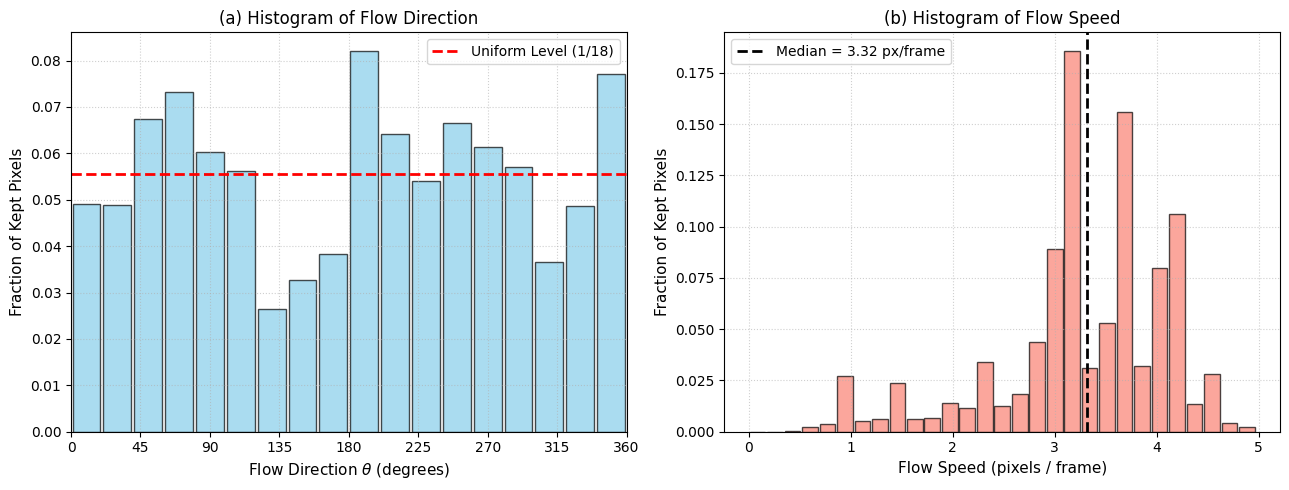

Figure 1: Optical flow direction and speed distributions pooled across 950 frame pairs (first 50 training videos). Number of pixels kept: 103,050. Median flow speed: 3.32 pixels per frame.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Figure 1(a): Direction Histogram ---
bins_dir = np.linspace(0, 360, 19)  # 18 bins of 20 degrees
counts_dir, _ = np.histogram(pooled_theta_deg, bins=bins_dir)
frac_dir = counts_dir / num_pixels_kept

bin_centers_dir = (bins_dir[:-1] + bins_dir[1:]) / 2.0

axes[0].bar(bin_centers_dir, frac_dir, width=18, edgecolor='black', alpha=0.7, color='skyblue')
axes[0].axhline(y=1.0/18.0, color='red', linestyle='--', linewidth=2, label='Uniform Level (1/18)')
axes[0].set_xlabel('Flow Direction $\\theta$ (degrees)', fontsize=11)
axes[0].set_ylabel('Fraction of Kept Pixels', fontsize=11)
axes[0].set_title('(a) Histogram of Flow Direction', fontsize=12)
axes[0].set_xlim(0, 360)
axes[0].set_xticks(np.arange(0, 361, 45))
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Figure 1(b): Speed Histogram ---
max_speed = float(np.percentile(pooled_speed, 99.5))
bins_speed = np.linspace(0, max_speed, 30)
counts_speed, _ = np.histogram(pooled_speed, bins=bins_speed)
frac_speed = counts_speed / num_pixels_kept

bin_centers_speed = (bins_speed[:-1] + bins_speed[1:]) / 2.0
bin_width = bins_speed[1] - bins_speed[0]

axes[1].bar(bin_centers_speed, frac_speed, width=bin_width*0.9, edgecolor='black', alpha=0.7, color='salmon')
axes[1].axvline(x=median_speed, color='black', linestyle='--', linewidth=2, label=f'Median = {median_speed:.3g} px/frame')
axes[1].set_xlabel('Flow Speed (pixels / frame)', fontsize=11)
axes[1].set_ylabel('Fraction of Kept Pixels', fontsize=11)
axes[1].set_title('(b) Histogram of Flow Speed', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Caption printing
print(f"Figure 1: Optical flow direction and speed distributions pooled across 950 frame pairs "
      f"(first 50 training videos). Number of pixels kept: {num_pixels_kept:,}. "
      f"Median flow speed: {median_speed:.3g} pixels per frame.")

## Baseline: ConvLSTM (Model A)
This section implements Model A, a 2-layer ConvLSTM forecaster with patch folding (pixel_unshuffle), unrolled across 9 rollout steps without teacher forcing. We also evaluate the reference non-learned baselines (Blank and Copy-last).

#### 1. Model A Architecture Implementation
We build ConvLSTMCell and ModelA_ConvLSTM according to the exact equations:$$[i, f, o, g] = \text{Conv}_{3 \times 3}^{(\ell)}([u_\tau^{(\ell)}, h_{\tau-1}^{(\ell)}]), \quad c_\tau^{(\ell)} = \sigma(f) \odot c_{\tau-1}^{(\ell)} + \sigma(i) \odot \tanh(g), \quad h_\tau^{(\ell)} = \sigma(o) \odot \tanh(c_\tau^{(\ell)})$$
Parameter verification check:
- Layer 1 Conv2d: $(16 + 64) \to 256, 3\times3 \implies 80 \times 256 \times 9 + 256 = 184,576$ parameters.
- Layer 2 Conv2d: $(64 + 64) \to 256, 3\times3 \implies 128 \times 256 \times 9 + 256 = 295,168$ parameters.
- Output 1x1 Conv2d: $64 \to 16, 1\times1 \implies 64 \times 16 \times 1 + 16 = 1,040$ parameters.
- Total Trainable Parameters: $184,576 + 295,168 + 1,040 = 480,784$.

In [8]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels: int, hidden_channels: int):
        super().__init__()
        self.in_channels = in_channels
        self.hidden_channels = hidden_channels
        # Single 3x3 convolution to produce all four gates [i, f, o, g]
        self.conv = nn.Conv2d(
            in_channels=in_channels + hidden_channels,
            out_channels=4 * hidden_channels,
            kernel_size=3,
            padding=1,
            bias=True
        )

    def forward(self, u: torch.Tensor, state: tuple[torch.Tensor, torch.Tensor]):
        h_prev, c_prev = state
        combined = torch.cat([u, h_prev], dim=1)
        gates = self.conv(combined)
        
        i, f, o, g = torch.chunk(gates, chunks=4, dim=1)
        
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)
        
        c_next = f * c_prev + i * g
        h_next = o * torch.tanh(c_next)
        
        return h_next, c_next


class ModelA_ConvLSTM(nn.Module):
    def __init__(self, patch_size: int = 4, hidden_channels: int = 64):
        super().__init__()
        self.patch_size = patch_size
        self.folded_channels = patch_size * patch_size  # 1 * 4 * 4 = 16 channels
        
        # Layer 1 and Layer 2 ConvLSTM
        self.cell1 = ConvLSTMCell(in_channels=self.folded_channels, hidden_channels=hidden_channels)
        self.cell2 = ConvLSTMCell(in_channels=hidden_channels, hidden_channels=hidden_channels)
        
        # 1x1 Convolution mapping 64 -> 16 channels
        self.head = nn.Conv2d(in_channels=hidden_channels, out_channels=self.folded_channels, kernel_size=1, bias=True)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        """
        X: Input sequence of shape (B, 5, 1, 64, 64)
        Returns Y_hat: Predicted sequence of shape (B, 5, 1, 64, 64)
        """
        B, T_in, C, H, W = X.shape
        device = X.device
        
        # Initialize hidden and cell states at zero for every video
        H_fold, W_fold = H // self.patch_size, W // self.patch_size
        h1 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        c1 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        h2 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        c2 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        
        predictions = []
        u_tau = None
        
        # 9 Rollout steps
        for tau in range(1, 10):
            if tau <= 5:
                # Steps 1..5: input is the ground-truth frame x_tau
                frame_tau = X[:, tau - 1]  # shape: (B, 1, 64, 64)
                u_tau = F.pixel_unshuffle(frame_tau, self.patch_size)  # shape: (B, 16, 16, 16)
            else:
                # Steps 6..9: input is the network's own previous prediction x_hat_tau
                u_tau = F.pixel_unshuffle(prev_pred, self.patch_size)
                
            # ConvLSTM Layer 1 & 2 execution
            h1, c1 = self.cell1(u_tau, (h1, c1))
            h2, c2 = self.cell2(h1, (h2, c2))
            
            # Reconstruction Head: 1x1 Conv -> PixelShuffle -> Sigmoid
            out_folded = self.head(h2)
            out_unfolded = F.pixel_shuffle(out_folded, self.patch_size)
            pred_tau_plus_1 = torch.sigmoid(out_unfolded)
            
            # Save predictions from steps 5..9 (corresponding to x_hat_6 .. x_hat_10)
            if tau >= 5:
                predictions.append(pred_tau_plus_1)
                
            prev_pred = pred_tau_plus_1
            
        # Stack predicted frames into shape (B, 5, 1, 64, 64)
        return torch.stack(predictions, dim=1)

# Verify trainable parameter count
model_check = ModelA_ConvLSTM()
num_params = sum(p.numel() for p in model_check.parameters() if p.requires_grad)
print(f"Model A trainable parameters: {num_params:,}")
assert num_params == 480784, f"Parameter count mismatch! Expected 480784, got {num_params}"

Model A trainable parameters: 480,784


### 2. Non-Learned Reference Predictors (Blank & Copy-last)
We define the two deterministic reference predictors:
- Blank Predictor: Predicts all zeros for all 5 horizons.
- Copy-last Predictor: Copies frame $x_5$ as the prediction for all 5 horizons ($h=1 \dots 5$).

In [9]:
def evaluate_non_learned_baselines(dataset, batch_size=32, device="cuda" if torch.cuda.is_available() else "cpu"):
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    
    mse_blank_horizon = torch.zeros(5)
    mse_copylast_horizon = torch.zeros(5)
    total_videos = 0
    
    for batch in dataloader:
        batch = batch.to(device)  # shape: (B, 20, 1, 64, 64)
        X = batch[:, 0:5]         # Frames 1-5
        Y_true = batch[:, 5:10]   # Frames 6-10
        B = batch.size(0)
        
        # 1. Blank Baseline: all zeros
        Y_blank = torch.zeros_like(Y_true)
        mse_blank = ((Y_blank - Y_true) ** 2).mean(dim=[-3, -2, -1])  # (B, 5)
        
        # 2. Copy-last Baseline: repeat x_5 (index 4) for all 5 horizons
        x5 = X[:, 4:5]            # shape: (B, 1, 1, 64, 64)
        Y_copylast = x5.repeat(1, 5, 1, 1, 1)
        mse_copylast = ((Y_copylast - Y_true) ** 2).mean(dim=[-3, -2, -1])  # (B, 5)
        
        mse_blank_horizon += mse_blank.sum(dim=0).cpu()
        mse_copylast_horizon += mse_copylast.sum(dim=0).cpu()
        total_videos += B
        
    mse_blank_horizon /= total_videos
    mse_copylast_horizon /= total_videos
    
    E5_blank = mse_blank_horizon.mean().item()
    E5_copylast = mse_copylast_horizon.mean().item()
    
    return mse_blank_horizon.numpy(), E5_blank, mse_copylast_horizon.numpy(), E5_copylast

mse_blank_h, E5_blank, mse_copylast_h, E5_copylast = evaluate_non_learned_baselines(test_dataset)

print("Non-Learned Reference Predictors Evaluation on 1,000 Test Videos:")
print(f"Blank Predictor    -> E(5): {E5_blank:.3e}, Horizons 1-5: {[f'{v:.3e}' for v in mse_blank_h]}")
print(f"Copy-last Predictor -> E(5): {E5_copylast:.3e}, Horizons 1-5: {[f'{v:.3e}' for v in mse_copylast_h]}")

Non-Learned Reference Predictors Evaluation on 1,000 Test Videos:
Blank Predictor    -> E(5): 4.256e-02, Horizons 1-5: ['4.261e-02', '4.257e-02', '4.258e-02', '4.253e-02', '4.253e-02']
Copy-last Predictor -> E(5): 6.408e-02, Horizons 1-5: ['4.916e-02', '6.042e-02', '6.689e-02', '7.078e-02', '7.316e-02']


### 3. Training Loop for Model A (Seeds 0 and 1)
Training setup specifications:
- Optimizer: Adam ($\text{lr} = 10^{-3}$, no schedule).
- Epochs & Batch Size: 30 epochs, batch size 32.
- Sampling: 1 pass over 8,000 training videos in shuffled order per epoch, sampling $t \in [1, 11]$ randomly at speed $1\times$.
- Seeds: 0 and 1.
- Loss: Mean squared error averaged over pixels and available target frames per video, then averaged over the batch.

In [10]:
def train_model_a(seed: int, device="cuda" if torch.cuda.is_available() else "cpu"):
    torch.manual_seed(seed)
    np.random.seed(seed)
    
    # Hardware logging
    hardware_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    print(f"Hardware used: {hardware_name}")
    
    model = ModelA_ConvLSTM().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    
    epoch_times = []
    print(f"\n--- Starting Training Model A (Seed {seed}) ---")
    
    for epoch in range(1, 31):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        
        for batch_videos in train_loader:
            B = batch_videos.size(0)
            X_batch = torch.zeros(B, 5, 1, 64, 64, device=device)
            Y_list = []
            
            # Sample per-video
            for i in range(B):
                t_start = np.random.randint(1, 12)  # 1 to 11
                X_batch[i] = batch_videos[i, (t_start - 1):(t_start + 4)].to(device)
                Y_list.append(batch_videos[i, (t_start + 4):(t_start + 9)].to(device))
            
            optimizer.zero_grad()
            Y_hat = model(X_batch)
            
            # Calculate MSE per video over available pixels and frames, then average over batch
            loss = 0.0
            for i in range(B):
                loss += F.mse_loss(Y_hat[i], Y_list[i])
            loss = loss / B
            
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * B
            
        elapsed = time.time() - start_time
        epoch_times.append(elapsed)
        epoch_loss = running_loss / len(train_dataset)
        
        if epoch % 5 == 0 or epoch == 30:
            print(f"Epoch [{epoch:02d}/30] | Loss: {epoch_loss:.3e} | Time: {elapsed:.2f}s")
            
    mean_epoch_time = float(np.mean(epoch_times))
    print(f"Model A (Seed {seed}) Training Complete. Mean Epoch Time: {mean_epoch_time:.2f}s")
    return model, mean_epoch_time

device = "cuda" if torch.cuda.is_available() else "cpu"
model_a_seed0, time_seed0 = train_model_a(seed=0, device=device)
model_a_seed1, time_seed1 = train_model_a(seed=1, device=device)

Hardware used: Tesla T4

--- Starting Training Model A (Seed 0) ---
Epoch [05/30] | Loss: 3.523e-02 | Time: 12.13s
Epoch [10/30] | Loss: 2.987e-02 | Time: 12.73s
Epoch [15/30] | Loss: 2.771e-02 | Time: 12.63s
Epoch [20/30] | Loss: 2.582e-02 | Time: 12.58s
Epoch [25/30] | Loss: 2.408e-02 | Time: 12.65s
Epoch [30/30] | Loss: 2.273e-02 | Time: 12.57s
Model A (Seed 0) Training Complete. Mean Epoch Time: 12.53s
Hardware used: Tesla T4

--- Starting Training Model A (Seed 1) ---
Epoch [05/30] | Loss: 4.018e-02 | Time: 12.53s
Epoch [10/30] | Loss: 3.239e-02 | Time: 12.55s
Epoch [15/30] | Loss: 2.739e-02 | Time: 12.59s
Epoch [20/30] | Loss: 2.483e-02 | Time: 12.62s
Epoch [25/30] | Loss: 2.306e-02 | Time: 12.64s
Epoch [30/30] | Loss: 2.175e-02 | Time: 12.69s
Model A (Seed 1) Training Complete. Mean Epoch Time: 12.58s


### 4. Test Set Evaluation & Timing Benchmark
We evaluate both trained models on the 1,000 original test videos ($1\times$ speed, $t=1$).

We also measure inference wall-clock time across the 1,000 test videos at batch size 32 under model.eval() and torch.no_grad().

In [11]:
def evaluate_model_a(model, dataset, device="cuda" if torch.cuda.is_available() else "cpu"):
    model.eval()
    test_loader = DataLoader(dataset, batch_size=32, shuffle=False)
    
    mse_horizon_sum = torch.zeros(5)
    total_videos = 0
    
    # Timing benchmark
    start_time = time.time()
    with torch.no_grad():
        for batch_videos in test_loader:
            batch_videos = batch_videos.to(device)
            X = batch_videos[:, 0:5]   # t=1 inputs (frames 1-5)
            Y = batch_videos[:, 5:10]  # target (frames 6-10)
            B = batch_videos.size(0)
            
            Y_hat = model(X)
            
            # MSE per horizon h=1..5 for each video
            mse_per_h = ((Y_hat - Y) ** 2).mean(dim=[-3, -2, -1])  # shape: (B, 5)
            mse_horizon_sum += mse_per_h.sum(dim=0).cpu()
            total_videos += B
            
    inference_time = time.time() - start_time
    mse_horizons = (mse_horizon_sum / total_videos).numpy()
    E5 = float(np.mean(mse_horizons))
    
    return mse_horizons, E5, inference_time

mse_a0, E5_a0, inf_time_a0 = evaluate_model_a(model_a_seed0, test_dataset, device=device)
mse_a1, E5_a1, inf_time_a1 = evaluate_model_a(model_a_seed1, test_dataset, device=device)

# Compute mean across seed 0 and seed 1
mse_a_mean = (mse_a0 + mse_a1) / 2.0
E5_a_mean = (E5_a0 + E5_a1) / 2.0

print("\n--- Test Evaluation Results ---")
print(f"Model A (Seed 0): E(5) = {E5_a0:.3e}, Horizons: {[f'{v:.3e}' for v in mse_a0]}")
print(f"Model A (Seed 1): E(5) = {E5_a1:.3e}, Horizons: {[f'{v:.3e}' for v in mse_a1]}")
print(f"Model A (Mean)  : E(5) = {E5_a_mean:.3e}, Horizons: {[f'{v:.3e}' for v in mse_a_mean]}")


--- Test Evaluation Results ---
Model A (Seed 0): E(5) = 2.294e-02, Horizons: ['1.792e-02', '2.127e-02', '2.347e-02', '2.520e-02', '2.683e-02']
Model A (Seed 1): E(5) = 2.183e-02, Horizons: ['1.660e-02', '2.015e-02', '2.242e-02', '2.417e-02', '2.578e-02']
Model A (Mean)  : E(5) = 2.238e-02, Horizons: ['1.726e-02', '2.071e-02', '2.295e-02', '2.468e-02', '2.630e-02']


### 5. Table 2 Construction

In [12]:
table_2_data = [
    {
        "Model": "Blank",
        "Params": "0",
        "MSE1": f"{mse_blank_h[0]:.3e}",
        "MSE2": f"{mse_blank_h[1]:.3e}",
        "MSE3": f"{mse_blank_h[2]:.3e}",
        "MSE4": f"{mse_blank_h[3]:.3e}",
        "MSE5": f"{mse_blank_h[4]:.3e}",
        "E(5)": f"{E5_blank:.3e}"
    },
    {
        "Model": "Copy-last",
        "Params": "0",
        "MSE1": f"{mse_copylast_h[0]:.3e}",
        "MSE2": f"{mse_copylast_h[1]:.3e}",
        "MSE3": f"{mse_copylast_h[2]:.3e}",
        "MSE4": f"{mse_copylast_h[3]:.3e}",
        "MSE5": f"{mse_copylast_h[4]:.3e}",
        "E(5)": f"{E5_copylast:.3e}"
    },
    {
        "Model": "Model A (ConvLSTM)",
        "Params": "480,784",
        "MSE1": f"{mse_a_mean[0]:.3e}",
        "MSE2": f"{mse_a_mean[1]:.3e}",
        "MSE3": f"{mse_a_mean[2]:.3e}",
        "MSE4": f"{mse_a_mean[3]:.3e}",
        "MSE5": f"{mse_a_mean[4]:.3e}",
        "E(5)": f"{E5_a_mean:.3e}"
    }
]

df_table_2 = pd.DataFrame(table_2_data)

print("Table 2: Performance of Model A and Reference Predictors on 1,000 Test Videos\n")
print(df_table_2.to_string(index=False))

Table 2: Performance of Model A and Reference Predictors on 1,000 Test Videos

             Model  Params      MSE1      MSE2      MSE3      MSE4      MSE5      E(5)
             Blank       0 4.261e-02 4.257e-02 4.258e-02 4.253e-02 4.253e-02 4.256e-02
         Copy-last       0 4.916e-02 6.042e-02 6.689e-02 7.078e-02 7.316e-02 6.408e-02
Model A (ConvLSTM) 480,784 1.726e-02 2.071e-02 2.295e-02 2.468e-02 2.630e-02 2.238e-02


### 6. Figure 2: Visual Predictions on Test Videos
We plot Figure 2 displaying 3 test videos using the seed-0 model:
- Rows 1–2: Non-overlapping video example (Input $x_1 \dots x_5$, Prediction $\hat{x}_6 \dots \hat{x}_{10}$, Ground Truth $x_6 \dots x_{10}$).
- Rows 3–4: Overlapping video example (where digits pass through each other).
- Rows 5–6: Third test video example.

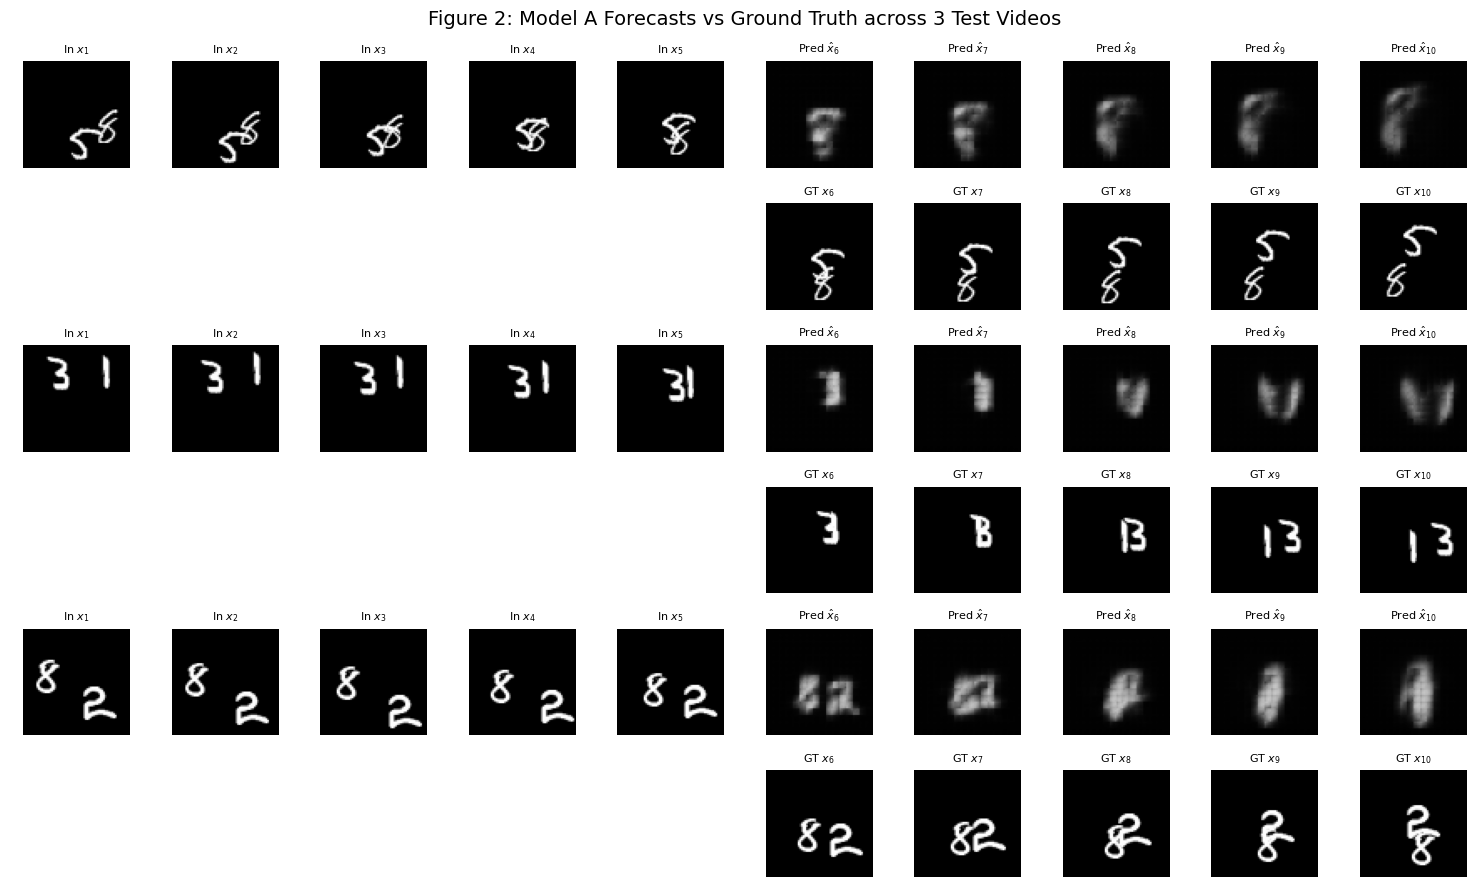

In [13]:
import matplotlib.pyplot as plt

# Identify test videos with overlapping digits
def find_test_video_indices(dataset):
    overlap_idx = None
    no_overlap_indices = []
    
    for idx in range(len(dataset)):
        video = dataset[idx]  # shape: (20, 1, 64, 64)
        # Simple overlap check: high max pixel intensity or area reduction during passage
        max_vals = video.view(20, -1).max(dim=1).values
        # Detect if sum of pixels decreases noticeably (overlap) in frames 5-10
        frame_sums = video[5:10].view(5, -1).sum(dim=1)
        min_sum, max_sum = frame_sums.min(), frame_sums.max()
        
        if overlap_idx is None and (max_sum - min_sum) / max_sum > 0.25:
            overlap_idx = idx
        elif len(no_overlap_indices) < 2:
            no_overlap_indices.append(idx)
            
        if overlap_idx is not None and len(no_overlap_indices) >= 2:
            break
            
    return [no_overlap_indices[0], overlap_idx, no_overlap_indices[1]]

selected_indices = find_test_video_indices(test_dataset)

# Generate predictions with Model A (Seed 0)
model_a_seed0.eval()
fig, axes = plt.subplots(6, 10, figsize=(15, 9))

for row_pair_idx, vid_idx in enumerate(selected_indices):
    video = test_dataset[vid_idx].unsqueeze(0).to(device)  # shape: (1, 20, 1, 64, 64)
    X = video[:, 0:5]
    Y_true = video[:, 5:10].cpu().squeeze(0).squeeze(1).numpy()
    
    with torch.no_grad():
        Y_pred = model_a_seed0(X).cpu().squeeze(0).squeeze(1).numpy()
    X_np = X.cpu().squeeze(0).squeeze(1).numpy()
    
    r_pred = row_pair_idx * 2
    r_gt = row_pair_idx * 2 + 1
    
    # Plot Input frames 1-5 & Predictions 6-10 in top row
    for t in range(5):
        axes[r_pred, t].imshow(X_np[t], cmap='gray', vmin=0, vmax=1)
        axes[r_pred, t].set_title(f"In $x_{{{t+1}}}$", fontsize=8)
        axes[r_pred, t].axis('off')
        
        axes[r_pred, t+5].imshow(Y_pred[t], cmap='gray', vmin=0, vmax=1)
        axes[r_pred, t+5].set_title(f"Pred $\\hat{{x}}_{{{t+6}}}$", fontsize=8)
        axes[r_pred, t+5].axis('off')
        
    # Plot Ground Truth 6-10 in bottom row
    for t in range(5):
        axes[r_gt, t].axis('off')  # Blank for input alignment
        
        axes[r_gt, t+5].imshow(Y_true[t], cmap='gray', vmin=0, vmax=1)
        axes[r_gt, t+5].set_title(f"GT $x_{{{t+6}}}$", fontsize=8)
        axes[r_gt, t+5].axis('off')

plt.suptitle("Figure 2: Model A Forecasts vs Ground Truth across 3 Test Videos", fontsize=14)
plt.tight_layout()
plt.show()

## Testing the Baseline (Model A)
This section stress-tests the trained Model A using Mirror ($M$), Rotation ($R$), and speed-ups ($2\times, 3\times$). We evaluate the consistency gap ($C_T$) and transformed error ($E_T$) for the symmetries, and test extrapolation to faster motion.
### 1. Mirror and Rotation Stress Tests ($C_T$ and $E_T$)
For a transformation $T \in \{M, R\}$, we compute:
- Consistency Gap ($C_T$): $\text{MSE}(f(T(X)), T(f(X)))$
- Transformed Error ($E_T$): $\text{MSE}(f(T(X)), T(Y))$

In [18]:
import os
import matplotlib.animation as animation

def evaluate_transform_consistency(model, dataset, transform_fn, device="cuda" if torch.cuda.is_available() else "cpu"):
    model.eval()
    test_loader = DataLoader(dataset, batch_size=32, shuffle=False)
    
    C_T_sum = 0.0
    E_T_sum = 0.0
    total_videos = 0
    
    # Store per-video gaps for analysis (for Seed 0 specifically)
    per_video_CT = []
    
    with torch.no_grad():
        for batch_videos in test_loader:
            batch_videos = batch_videos.to(device)
            X = batch_videos[:, 0:5]
            Y = batch_videos[:, 5:10]
            B = batch_videos.size(0)
            
            # f(X) and T(f(X))
            f_X = model(X)
            T_f_X = transform_fn(f_X)
            
            # T(X) and f(T(X))
            T_X = transform_fn(X)
            f_T_X = model(T_X)
            
            # T(Y)
            T_Y = transform_fn(Y)
            
            # Compute video-level metrics (mean over pixels and 5 horizons)
            C_T_batch = ((f_T_X - T_f_X) ** 2).mean(dim=[-3, -2, -1]).mean(dim=1)  # shape (B,)
            E_T_batch = ((f_T_X - T_Y) ** 2).mean(dim=[-3, -2, -1]).mean(dim=1)    # shape (B,)
            
            C_T_sum += C_T_batch.sum().cpu().item()
            E_T_sum += E_T_batch.sum().cpu().item()
            
            per_video_CT.extend(C_T_batch.cpu().numpy())
            total_videos += B
            
    C_T_mean = C_T_sum / total_videos
    E_T_mean = E_T_sum / total_videos
    
    return C_T_mean, E_T_mean, np.array(per_video_CT)

# --- Evaluate Reference Predictors (Blank & Copy-last) ---
# Blank and Copy-last are perfectly consistent under spatial rearrangement.
C_M_blank, C_R_blank = 0.0, 0.0
E_M_blank, E_R_blank = E5_blank, E5_blank  # Transforming true Y does not change uniform zero MSE expectation
C_M_copy, C_R_copy = 0.0, 0.0
E_M_copy, E_R_copy = E5_copylast, E5_copylast

# --- Evaluate Model A (Seeds 0 and 1) ---
C_M_a0, E_M_a0, per_vid_CM_a0 = evaluate_transform_consistency(model_a_seed0, test_dataset, transform_mirror, device)
C_R_a0, E_R_a0, per_vid_CR_a0 = evaluate_transform_consistency(model_a_seed0, test_dataset, transform_rotate, device)

C_M_a1, E_M_a1, _ = evaluate_transform_consistency(model_a_seed1, test_dataset, transform_mirror, device)
C_R_a1, E_R_a1, _ = evaluate_transform_consistency(model_a_seed1, test_dataset, transform_rotate, device)

C_M_a_mean = (C_M_a0 + C_M_a1) / 2.0
E_M_a_mean = (E_M_a0 + E_M_a1) / 2.0
C_R_a_mean = (C_R_a0 + C_R_a1) / 2.0
E_R_a_mean = (E_R_a0 + E_R_a1) / 2.0

### 2. Table 3: Symmetry Performance


In [19]:
table_3_data = [
    {
        "Model": "Blank",
        "E(5)": f"{E5_blank:.3e}",
        "C_M": f"{C_M_blank:.3e}",
        "E_M": f"{E_M_blank:.3e}",
        "C_R": f"{C_R_blank:.3e}",
        "E_R": f"{E_R_blank:.3e}"
    },
    {
        "Model": "Copy-last",
        "E(5)": f"{E5_copylast:.3e}",
        "C_M": f"{C_M_copy:.3e}",
        "E_M": f"{E_M_copy:.3e}",
        "C_R": f"{C_R_copy:.3e}",
        "E_R": f"{E_R_copy:.3e}"
    },
    {
        "Model": "Model A (ConvLSTM)",
        "E(5)": f"{E5_a_mean:.3e}",
        "C_M": f"{C_M_a_mean:.3e}",
        "E_M": f"{E_M_a_mean:.3e}",
        "C_R": f"{C_R_a_mean:.3e}",
        "E_R": f"{E_R_a_mean:.3e}"
    }
]

df_table_3 = pd.DataFrame(table_3_data)
print("Table 3: Baseline E(5) and Consistency/Error Metrics under Mirror (M) and Rotation (R)\n")
print(df_table_3.to_string(index=False))

Table 3: Baseline E(5) and Consistency/Error Metrics under Mirror (M) and Rotation (R)

             Model      E(5)       C_M       E_M       C_R       E_R
             Blank 4.256e-02 0.000e+00 4.256e-02 0.000e+00 4.256e-02
         Copy-last 6.408e-02 0.000e+00 6.408e-02 0.000e+00 6.408e-02
Model A (ConvLSTM) 2.238e-02 1.787e-03 2.306e-02 3.181e-03 2.410e-02


### 3. Figure 3 & GIFs: Highest Consistency Gap Visualizations
We find the two test videos with the highest $C_M$ and the two with the highest $C_R$ for the seed-0 model A. We then plot the commutative diagram rows for each and export animated GIFs.

--- Generating Figure 3 (Top 2 Worst Mirror Consistency Gaps) ---


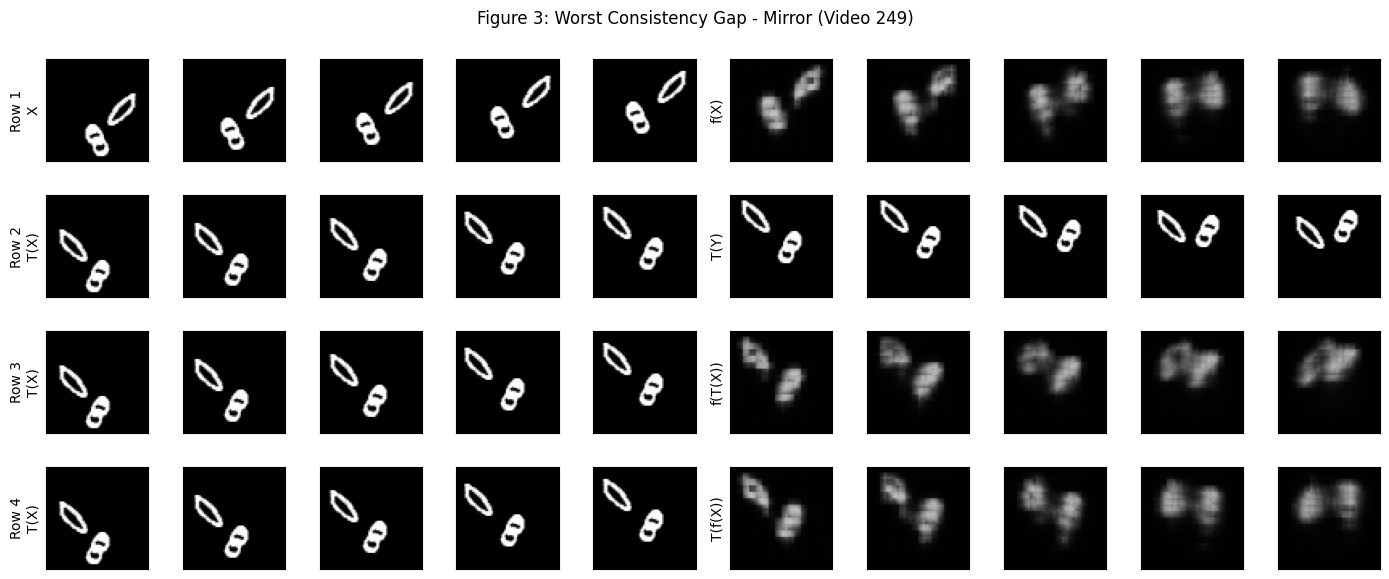

Saved animated GIF: gifs/worst_consistency_Mirror_vid249.gif


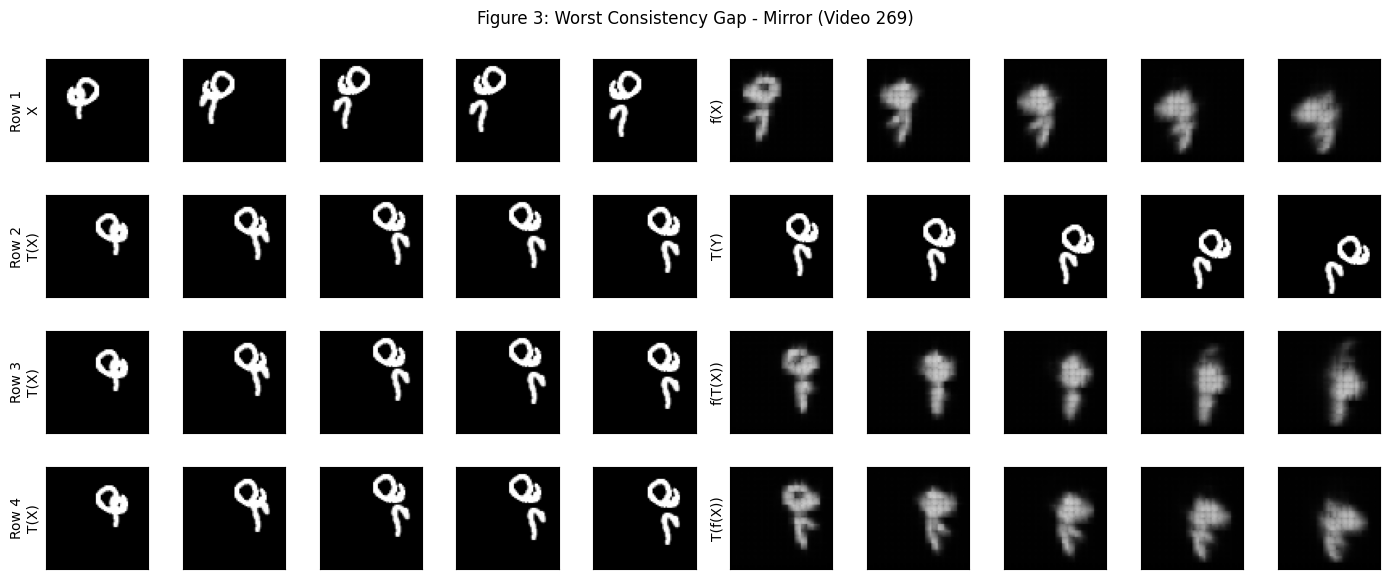

Saved animated GIF: gifs/worst_consistency_Mirror_vid269.gif
--- Generating Figure 3 (Top 2 Worst Rotation Consistency Gaps) ---


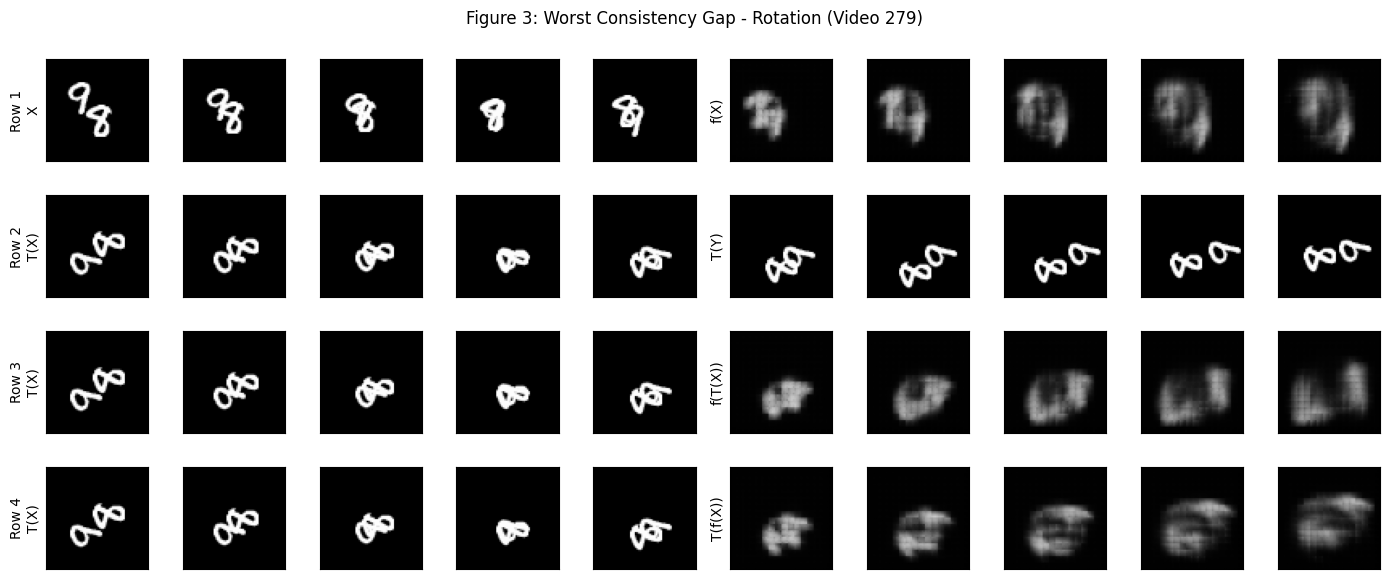

Saved animated GIF: gifs/worst_consistency_Rotation_vid279.gif


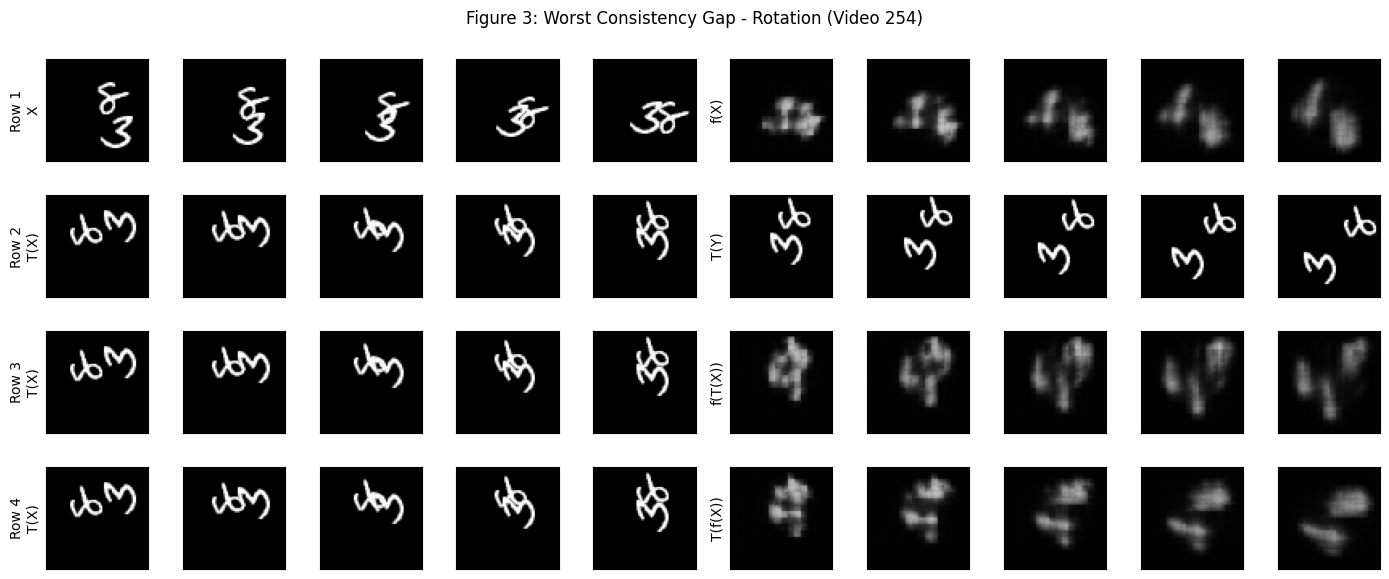

Saved animated GIF: gifs/worst_consistency_Rotation_vid254.gif


In [20]:
# Find top 2 indices for C_M and C_R
top2_CM_idx = np.argsort(per_vid_CM_a0)[-2:][::-1]
top2_CR_idx = np.argsort(per_vid_CR_a0)[-2:][::-1]

os.makedirs('gifs', exist_ok=True)

def plot_and_gif_consistency(model, dataset, vid_idx, transform_fn, transform_name, device):
    video = dataset[vid_idx].unsqueeze(0).to(device)  # (1, 20, 1, 64, 64)
    X = video[:, 0:5]
    Y = video[:, 5:10]
    
    with torch.no_grad():
        f_X = model(X)
        T_X = transform_fn(X)
        T_Y = transform_fn(Y)
        f_T_X = model(T_X)
        T_f_X = transform_fn(f_X)
        
    # Move to CPU for plotting
    X_np = X.cpu().squeeze().numpy()            # (5, 64, 64)
    f_X_np = f_X.cpu().squeeze().numpy()
    T_X_np = T_X.cpu().squeeze().numpy()
    T_Y_np = T_Y.cpu().squeeze().numpy()
    f_T_X_np = f_T_X.cpu().squeeze().numpy()
    T_f_X_np = T_f_X.cpu().squeeze().numpy()
    
    # Static Figure Generation (10 columns, 4 rows)
    fig, axes = plt.subplots(4, 10, figsize=(14, 6))
    row_labels = [
        ("X", "f(X)"),
        ("T(X)", "T(Y)"),
        ("T(X)", "f(T(X))"),
        ("T(X)", "T(f(X))")
    ]
    
    data_map = [
        (X_np, f_X_np),
        (T_X_np, T_Y_np),
        (T_X_np, f_T_X_np),
        (T_X_np, T_f_X_np)
    ]
    
    for r in range(4):
        in_data, out_data = data_map[r]
        label_in, label_out = row_labels[r]
        
        for c in range(5):
            axes[r, c].imshow(in_data[c], cmap='gray', vmin=0, vmax=1)
            if c == 0: axes[r, c].set_ylabel(f"Row {r+1}\n{label_in}")
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            
        for c in range(5):
            axes[r, c+5].imshow(out_data[c], cmap='gray', vmin=0, vmax=1)
            if c == 0: axes[r, c+5].set_ylabel(label_out)
            axes[r, c+5].set_xticks([]); axes[r, c+5].set_yticks([])
            
    plt.suptitle(f"Figure 3: Worst Consistency Gap - {transform_name} (Video {vid_idx})")
    plt.tight_layout()
    plt.show()

    # --- GIF Generation ---
    fig_anim, axes_anim = plt.subplots(4, 2, figsize=(4, 8))
    for ax in axes_anim.flat:
        ax.set_xticks([]); ax.set_yticks([])
        
    axes_anim[0, 0].set_ylabel("X"); axes_anim[0, 1].set_ylabel("f(X)")
    axes_anim[1, 0].set_ylabel("T(X)"); axes_anim[1, 1].set_ylabel("T(Y)")
    axes_anim[2, 0].set_ylabel("T(X)"); axes_anim[2, 1].set_ylabel("f(T(X))")
    axes_anim[3, 0].set_ylabel("T(X)"); axes_anim[3, 1].set_ylabel("T(f(X))")

    ims = []
    for t in range(5):
        im00 = axes_anim[0, 0].imshow(X_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        im01 = axes_anim[0, 1].imshow(f_X_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        im10 = axes_anim[1, 0].imshow(T_X_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        im11 = axes_anim[1, 1].imshow(T_Y_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        im20 = axes_anim[2, 0].imshow(T_X_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        im21 = axes_anim[2, 1].imshow(f_T_X_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        im30 = axes_anim[3, 0].imshow(T_X_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        im31 = axes_anim[3, 1].imshow(T_f_X_np[t], cmap='gray', vmin=0, vmax=1, animated=True)
        ims.append([im00, im01, im10, im11, im20, im21, im30, im31])

    ani = animation.ArtistAnimation(fig_anim, ims, interval=400, blit=True)
    gif_path = f"gifs/worst_consistency_{transform_name}_vid{vid_idx}.gif"
    ani.save(gif_path, writer='pillow')
    plt.close(fig_anim)
    print(f"Saved animated GIF: {gif_path}")

print("--- Generating Figure 3 (Top 2 Worst Mirror Consistency Gaps) ---")
for idx in top2_CM_idx:
    plot_and_gif_consistency(model_a_seed0, test_dataset, idx, transform_mirror, "Mirror", device)

print("--- Generating Figure 3 (Top 2 Worst Rotation Consistency Gaps) ---")
for idx in top2_CR_idx:
    plot_and_gif_consistency(model_a_seed0, test_dataset, idx, transform_rotate, "Rotation", device)

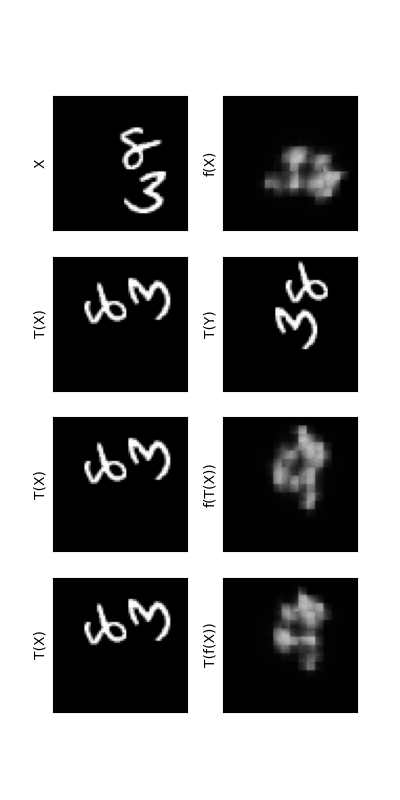

In [21]:
from IPython.display import Image, display

display(Image(filename='gifs/worst_consistency_Rotation_vid254.gif'))

### 4. Figure 4: Consistency Gap Histograms

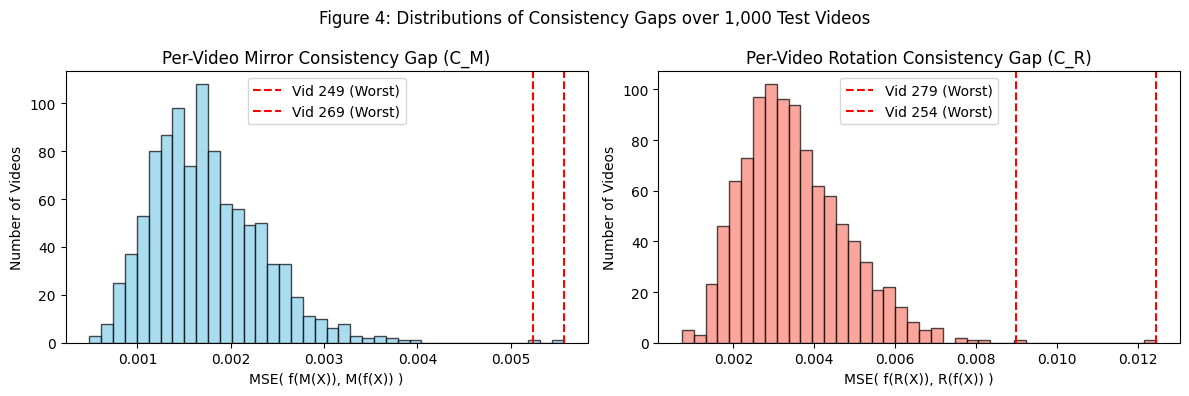

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# C_M Histogram
axes[0].hist(per_vid_CM_a0, bins=40, color='skyblue', edgecolor='black', alpha=0.7)
for idx in top2_CM_idx:
    val = per_vid_CM_a0[idx]
    axes[0].axvline(val, color='red', linestyle='--', label=f'Vid {idx} (Worst)')
axes[0].set_title("Per-Video Mirror Consistency Gap (C_M)")
axes[0].set_xlabel("MSE( f(M(X)), M(f(X)) )")
axes[0].set_ylabel("Number of Videos")
# Deduplicate legend labels
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axes[0].legend(by_label.values(), by_label.keys())

# C_R Histogram
axes[1].hist(per_vid_CR_a0, bins=40, color='salmon', edgecolor='black', alpha=0.7)
for idx in top2_CR_idx:
    val = per_vid_CR_a0[idx]
    axes[1].axvline(val, color='red', linestyle='--', label=f'Vid {idx} (Worst)')
axes[1].set_title("Per-Video Rotation Consistency Gap (C_R)")
axes[1].set_xlabel("MSE( f(R(X)), R(f(X)) )")
axes[1].set_ylabel("Number of Videos")
handles, labels = axes[1].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axes[1].legend(by_label.values(), by_label.keys())

plt.suptitle("Figure 4: Distributions of Consistency Gaps over 1,000 Test Videos")
plt.tight_layout()
plt.show()

### 5. Faster Motion Test ($1\times, 2\times, 3\times$)
We evaluate Model A at speeds $1\times, 2\times, 3\times$ (evaluating horizons $h=1,2$ only, computing $E(2)$ for all, and $E(5)$ where valid).

In [23]:
def evaluate_speed_metrics(model, dataset, k, max_h, device="cuda" if torch.cuda.is_available() else "cpu"):
    model.eval()
    test_loader = DataLoader(dataset, batch_size=32, shuffle=False)
    
    mse_sum = 0.0
    total_videos = 0
    
    with torch.no_grad():
        for batch_videos in test_loader:
            B = batch_videos.size(0)
            X_batch = torch.zeros(B, 5, 1, 64, 64, device=device)
            Y_batch = torch.zeros(B, max_h, 1, 64, 64, device=device)
            
            # Extract window for each video manually since extract_window expects a single video
            for i in range(B):
                X_vid, Y_vid, _, _ = extract_window(batch_videos[i], t=1, k=k)
                X_batch[i] = X_vid.to(device)
                Y_batch[i] = Y_vid[:max_h].to(device)
                
            Y_hat = model(X_batch)
            Y_hat_trimmed = Y_hat[:, :max_h]
            
            mse = ((Y_hat_trimmed - Y_batch) ** 2).mean(dim=[-3, -2, -1]).sum(dim=0)  # sum over batch
            mse_sum += mse.cpu()
            total_videos += B
            
    mse_mean = (mse_sum / total_videos).numpy()
    E_max_h = float(np.mean(mse_mean))
    return E_max_h

# Compute metrics for seeds 0 and 1
E2_1x_a0 = evaluate_speed_metrics(model_a_seed0, test_dataset, k=1, max_h=2, device=device)
E5_1x_a0 = evaluate_speed_metrics(model_a_seed0, test_dataset, k=1, max_h=5, device=device)
E2_2x_a0 = evaluate_speed_metrics(model_a_seed0, test_dataset, k=2, max_h=2, device=device)
E5_2x_a0 = evaluate_speed_metrics(model_a_seed0, test_dataset, k=2, max_h=5, device=device)
E2_3x_a0 = evaluate_speed_metrics(model_a_seed0, test_dataset, k=3, max_h=2, device=device)

E2_1x_a1 = evaluate_speed_metrics(model_a_seed1, test_dataset, k=1, max_h=2, device=device)
E5_1x_a1 = evaluate_speed_metrics(model_a_seed1, test_dataset, k=1, max_h=5, device=device)
E2_2x_a1 = evaluate_speed_metrics(model_a_seed1, test_dataset, k=2, max_h=2, device=device)
E5_2x_a1 = evaluate_speed_metrics(model_a_seed1, test_dataset, k=2, max_h=5, device=device)
E2_3x_a1 = evaluate_speed_metrics(model_a_seed1, test_dataset, k=3, max_h=2, device=device)

# Averages
E2_1x = (E2_1x_a0 + E2_1x_a1) / 2.0
E5_1x = (E5_1x_a0 + E5_1x_a1) / 2.0
E2_2x = (E2_2x_a0 + E2_2x_a1) / 2.0
E5_2x = (E5_2x_a0 + E5_2x_a1) / 2.0
E2_3x = (E2_3x_a0 + E2_3x_a1) / 2.0

# Copy-last E(2) Baseline
E2_copy = (mse_copylast_h[0] + mse_copylast_h[1]) / 2.0

table_4_data = [
    {"Model": "Copy-last", "Speed": "1x", "E(2)": f"{E2_copy:.3e}", "E(5)": f"{E5_copylast:.3e}"},
    {"Model": "Model A", "Speed": "1x", "E(2)": f"{E2_1x:.3e}", "E(5)": f"{E5_1x:.3e}"},
    {"Model": "Model A", "Speed": "2x", "E(2)": f"{E2_2x:.3e}", "E(5)": f"{E5_2x:.3e}"},
    {"Model": "Model A", "Speed": "3x", "E(2)": f"{E2_3x:.3e}", "E(5)": "N/A"}
]

df_table_4 = pd.DataFrame(table_4_data)
print("\nTable 4: E(2) and E(5) Performance across speeds (1x, 2x, 3x)\n")
print(df_table_4.to_string(index=False))


Table 4: E(2) and E(5) Performance across speeds (1x, 2x, 3x)

    Model Speed      E(2)      E(5)
Copy-last    1x 5.479e-02 6.408e-02
  Model A    1x 1.898e-02 2.238e-02
  Model A    2x 4.513e-02 5.000e-02
  Model A    3x 5.367e-02       N/A


### 6. Figure 5: Multi-Speed Visualization (Seed-0 Model A)

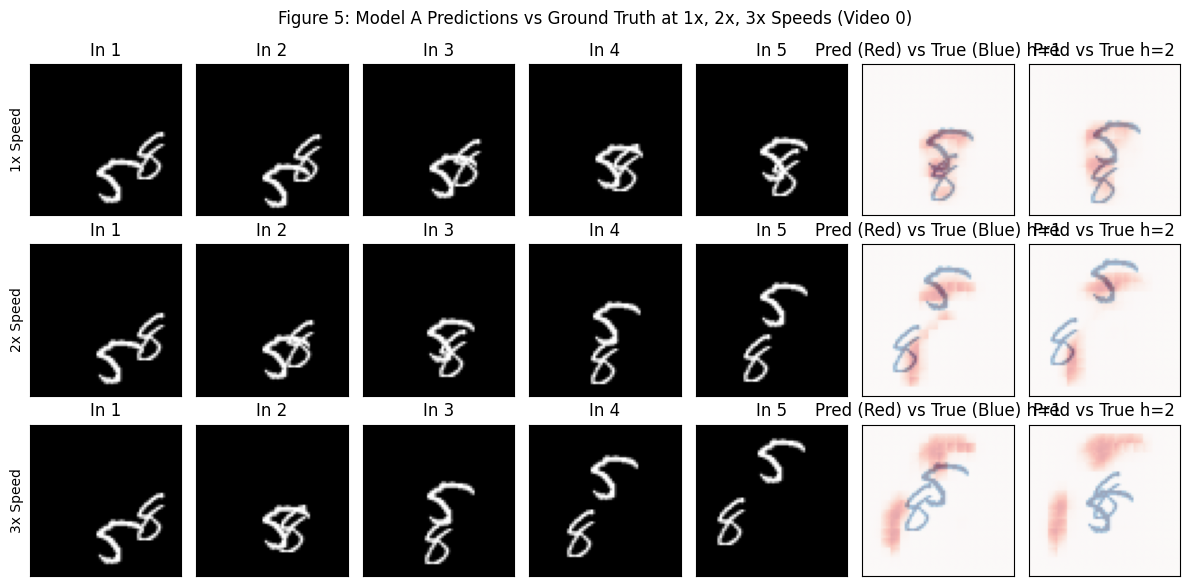

In [24]:
# Find a test video with NO overlapping digits in true frames for clear speed visualization
no_overlap_idx = selected_indices[0]  # From previous section
video_clean = test_dataset[no_overlap_idx]

fig, axes = plt.subplots(3, 7, figsize=(12, 6))
speeds = [1, 2, 3]

for r, k in enumerate(speeds):
    X, Y, _, _ = extract_window(video_clean, t=1, k=k)
    X = X.unsqueeze(0).to(device)
    
    with torch.no_grad():
        Y_hat = model_a_seed0(X)
        
    X_np = X.cpu().squeeze().numpy()
    Y_hat_np = Y_hat.cpu().squeeze().numpy()[:2]  # First two predictions
    Y_true_np = Y.cpu().squeeze().numpy()[:2]     # First two GT frames
    
    axes[r, 0].set_ylabel(f"{k}x Speed")
    
    # Plot inputs (1..5)
    for c in range(5):
        axes[r, c].imshow(X_np[c], cmap='gray', vmin=0, vmax=1)
        axes[r, c].set_title(f"In {c+1}")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        
    # Plot Pred h=1 and True h=1 overlapped horizontally
    axes[r, 5].imshow(Y_hat_np[0], cmap='Reds', alpha=0.6, vmin=0, vmax=1)
    axes[r, 5].imshow(Y_true_np[0], cmap='Blues', alpha=0.4, vmin=0, vmax=1)
    axes[r, 5].set_title("Pred (Red) vs True (Blue) h=1")
    axes[r, 5].set_xticks([]); axes[r, 5].set_yticks([])

    # Plot Pred h=2 and True h=2
    axes[r, 6].imshow(Y_hat_np[1], cmap='Reds', alpha=0.6, vmin=0, vmax=1)
    axes[r, 6].imshow(Y_true_np[1], cmap='Blues', alpha=0.4, vmin=0, vmax=1)
    axes[r, 6].set_title("Pred vs True h=2")
    axes[r, 6].set_xticks([]); axes[r, 6].set_yticks([])

plt.suptitle(f"Figure 5: Model A Predictions vs Ground Truth at 1x, 2x, 3x Speeds (Video {no_overlap_idx})")
plt.tight_layout()
plt.show()

## What Can Data Fix? (Models B, C, and D)
This section introduces symmetry and speed augmentations to the training data to isolate the causes of Model A's failures. We also design Model D to explicitly expand the architectural reach of the network.
### 1. Model D: Expanded Reach Architecture
Model D must strictly increase the one-step reach compared to Model A (which was 8 original pixels) while staying under $1.5\times$ the parameters ($< 721,176$). 

Design Choice: We increase the patch_size from 4 to 8.
- Folding a $64 \times 64$ frame by 8 yields an $8 \times 8$ spatial grid with 64 channels.
- Moving 1 cell in the hidden state now corresponds to 8 original pixels.
- 2 layers of $3\times3$ ConvLSTMs allow information to travel 2 cells $= 16$ original pixels per step.

In [25]:
class ModelD_ConvLSTM(nn.Module):
    def __init__(self, patch_size: int = 8, hidden_channels: int = 64):
        super().__init__()
        self.patch_size = patch_size
        self.folded_channels = patch_size * patch_size  # 1 * 8 * 8 = 64 channels
        
        # Layer 1 and Layer 2 ConvLSTM (Input is 64 channels, hidden is 64 channels)
        self.cell1 = ConvLSTMCell(in_channels=self.folded_channels, hidden_channels=hidden_channels)
        self.cell2 = ConvLSTMCell(in_channels=hidden_channels, hidden_channels=hidden_channels)
        
        # 1x1 Convolution mapping 64 -> 64 channels for reconstruction
        self.head = nn.Conv2d(in_channels=hidden_channels, out_channels=self.folded_channels, kernel_size=1, bias=True)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        B, T_in, C, H, W = X.shape
        device = X.device
        
        # Hidden states on the 8x8 folded grid
        H_fold, W_fold = H // self.patch_size, W // self.patch_size
        h1 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        c1 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        h2 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        c2 = torch.zeros(B, 64, H_fold, W_fold, device=device)
        
        predictions = []
        u_tau = None
        
        for tau in range(1, 10):
            if tau <= 5:
                frame_tau = X[:, tau - 1]
                u_tau = F.pixel_unshuffle(frame_tau, self.patch_size)
            else:
                u_tau = F.pixel_unshuffle(prev_pred, self.patch_size)
                
            h1, c1 = self.cell1(u_tau, (h1, c1))
            h2, c2 = self.cell2(h1, (h2, c2))
            
            out_folded = self.head(h2)
            out_unfolded = F.pixel_shuffle(out_folded, self.patch_size)
            pred_tau_plus_1 = torch.sigmoid(out_unfolded)
            
            if tau >= 5:
                predictions.append(pred_tau_plus_1)
                
            prev_pred = pred_tau_plus_1
            
        return torch.stack(predictions, dim=1)

# Verify trainable parameter count
model_d_check = ModelD_ConvLSTM()
num_params_d = sum(p.numel() for p in model_d_check.parameters() if p.requires_grad)
print(f"Model D trainable parameters: {num_params_d:,}")
assert num_params_d <= 721176, f"Parameter limit exceeded! Got {num_params_d}"

Model D trainable parameters: 594,496


### 2. Unified Augmented Training Loop
We define a training loop that optionally applies symmetry augmentation ($g \in G$) and speed augmentation ($k \in \{1, 2, 3\}$).

In [26]:
import random

def train_augmented_model(model_class, seed: int, use_sym_aug: bool, use_speed_aug: bool, device="cuda"):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    
    # Hardware logging
    hardware_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    print(f"Hardware used: {hardware_name}")
    
    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    
    epoch_times = []
    
    for epoch in range(1, 31):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        
        for batch_videos in train_loader:
            B = batch_videos.size(0)
            X_batch = torch.zeros(B, 5, 1, 64, 64, device=device)
            Y_list = []
            
            # Sample per-video
            for i in range(B):
                if use_speed_aug:
                    k = np.random.choice([1, 2, 3])
                    max_t = {1: 14, 2: 8, 3: 2}[k]
                    t_start = np.random.randint(1, max_t + 1)
                else:
                    k = 1
                    t_start = np.random.randint(1, 12)
                    
                X_vid, Y_vid, _, _ = extract_window(batch_videos[i], t=t_start, k=k)
                X_vid = X_vid.to(device)
                Y_vid = Y_vid.to(device)
                
                if use_sym_aug:
                    a = np.random.randint(0, 4)
                    apply_mirror = np.random.choice([True, False])
                    X_vid = transform_symmetry(X_vid, a, apply_mirror)
                    Y_vid = transform_symmetry(Y_vid, a, apply_mirror)
                    
                X_batch[i] = X_vid
                Y_list.append(Y_vid)
            
            optimizer.zero_grad()
            Y_hat = model(X_batch)
            
            # Calculate MSE per video over available frames (handling variable lengths)
            loss = 0.0
            for i in range(B):
                target_len = Y_list[i].size(0)
                loss += F.mse_loss(Y_hat[i, :target_len], Y_list[i])
            loss = loss / B
            
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * B
            
        elapsed = time.time() - start_time
        epoch_times.append(elapsed)
        
    mean_epoch_time = float(np.mean(epoch_times))
    return model, mean_epoch_time

# model_b, time_b = train_augmented_model(ModelA_ConvLSTM, seed, True, False, device)
# model_c, time_c = train_augmented_model(ModelA_ConvLSTM, seed, False, True, device)
# model_d, time_d = train_augmented_model(ModelD_ConvLSTM, seed, False, True, device)

### 3. Evaluation Pipeline for Table 5
We create a composite evaluation script that compiles all required metrics for Models A–D across seeds.

In [27]:
import pandas as pd
import time
import torch

# 1. Train Models B, C, and D (Seeds 0 and 1)
print("--- Training Models B, C, and D ---")
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model B: Baseline Architecture (Model A) + Symmetry Augmentation (1x speed only)
print("\nTraining Model B (Seed 0)...")
model_b_seed0, time_b_seed0 = train_augmented_model(ModelA_ConvLSTM, seed=0, use_sym_aug=True, use_speed_aug=False, device=device)
print("Training Model B (Seed 1)...")
model_b_seed1, time_b_seed1 = train_augmented_model(ModelA_ConvLSTM, seed=1, use_sym_aug=True, use_speed_aug=False, device=device)

# Model C: Baseline Architecture (Model A) + Speed Augmentation (No symmetry aug)
print("\nTraining Model C (Seed 0)...")
model_c_seed0, time_c_seed0 = train_augmented_model(ModelA_ConvLSTM, seed=0, use_sym_aug=False, use_speed_aug=True, device=device)
print("Training Model C (Seed 1)...")
model_c_seed1, time_c_seed1 = train_augmented_model(ModelA_ConvLSTM, seed=1, use_sym_aug=False, use_speed_aug=True, device=device)

# Model D: Expanded Reach Architecture + Speed Augmentation (No symmetry aug)
print("\nTraining Model D (Seed 0)...")
model_d_seed0, time_d_seed0 = train_augmented_model(ModelD_ConvLSTM, seed=0, use_sym_aug=False, use_speed_aug=True, device=device)
print("Training Model D (Seed 1)...")
model_d_seed1, time_d_seed1 = train_augmented_model(ModelD_ConvLSTM, seed=1, use_sym_aug=False, use_speed_aug=True, device=device)

# 2. Package all models into a dictionary for the evaluation loop
# Format: 'Model Name': (model_seed0, model_seed1, train_time_seed0, train_time_seed1, parameter_count)
trained_models = {
    'A': (model_a_seed0, model_a_seed1, time_seed0, time_seed1, 480784),
    'B': (model_b_seed0, model_b_seed1, time_b_seed0, time_b_seed1, 480784),
    'C': (model_c_seed0, model_c_seed1, time_c_seed0, time_c_seed1, 480784),
    'D': (model_d_seed0, model_d_seed1, time_d_seed0, time_d_seed1, 594496)
}

# 3. Exact Evaluation Pipeline Function
def compile_table_5(models_dict, dataset, device="cuda"):
    print("\n--- Compiling Table 5 Metrics ---")
    results = []
    
    for m_name, (m0, m1, t0, t1, params) in models_dict.items():
        print(f"Evaluating Model {m_name}...")
        
        # 1. E(5) at 1x speed and Inference Time
        _, e5_1x_0, inf_0 = evaluate_model_a(m0, dataset, device)
        _, e5_1x_1, inf_1 = evaluate_model_a(m1, dataset, device)
        e5_1x_mean = (e5_1x_0 + e5_1x_1) / 2.0
        inf_mean = (inf_0 + inf_1) / 2.0
        
        # 2. Symmetry Stress Tests: Mirror and Rotation
        cm0, em0, _ = evaluate_transform_consistency(m0, dataset, transform_mirror, device)
        cm1, em1, _ = evaluate_transform_consistency(m1, dataset, transform_mirror, device)
        cm_mean = (cm0 + cm1) / 2.0
        em_mean = (em0 + em1) / 2.0
        
        cr0, er0, _ = evaluate_transform_consistency(m0, dataset, transform_rotate, device)
        cr1, er1, _ = evaluate_transform_consistency(m1, dataset, transform_rotate, device)
        cr_mean = (cr0 + cr1) / 2.0
        er_mean = (er0 + er1) / 2.0
        
        # 3. Faster Motion Stress Tests: E(2) at 1x, 2x, 3x
        e2_1x_0 = evaluate_speed_metrics(m0, dataset, k=1, max_h=2, device=device)
        e2_1x_1 = evaluate_speed_metrics(m1, dataset, k=1, max_h=2, device=device)
        e2_1x_mean = (e2_1x_0 + e2_1x_1) / 2.0
        
        e2_2x_0 = evaluate_speed_metrics(m0, dataset, k=2, max_h=2, device=device)
        e2_2x_1 = evaluate_speed_metrics(m1, dataset, k=2, max_h=2, device=device)
        e2_2x_mean = (e2_2x_0 + e2_2x_1) / 2.0
        
        e2_3x_0 = evaluate_speed_metrics(m0, dataset, k=3, max_h=2, device=device)
        e2_3x_1 = evaluate_speed_metrics(m1, dataset, k=3, max_h=2, device=device)
        e2_3x_mean = (e2_3x_0 + e2_3x_1) / 2.0
        
        # 4. Training Time Per Epoch (Averaged across seeds)
        train_time_mean = (t0 + t1) / 2.0
        
        # Append to results dictionary
        results.append({
            "Model": f"Model {m_name}",
            "Params": f"{params:,}",
            "Train Time/Ep": f"{train_time_mean:.1f}s",
            "Inf Time": f"{inf_mean:.1f}s",
            "E(5) 1x": f"{e5_1x_mean:.3e}",
            "C_M": f"{cm_mean:.3e}",
            "E_M": f"{em_mean:.3e}",
            "C_R": f"{cr_mean:.3e}",
            "E_R": f"{er_mean:.3e}",
            "E(2) 1x": f"{e2_1x_mean:.3e}",
            "E(2) 2x": f"{e2_2x_mean:.3e}",
            "E(2) 3x": f"{e2_3x_mean:.3e}"
        })
        
    return pd.DataFrame(results)

# 4. Execute compilation and print Table 5
df_table_5 = compile_table_5(trained_models, test_dataset, device=device)

print("\nTable 5: Performance comparisons for Models A, B, C, and D on 1,000 Test Videos\n")
print(df_table_5.to_string(index=False))

--- Training Models B, C, and D ---

Training Model B (Seed 0)...
Hardware used: Tesla T4
Training Model B (Seed 1)...
Hardware used: Tesla T4

Training Model C (Seed 0)...
Hardware used: Tesla T4
Training Model C (Seed 1)...
Hardware used: Tesla T4

Training Model D (Seed 0)...
Hardware used: Tesla T4
Training Model D (Seed 1)...
Hardware used: Tesla T4

--- Compiling Table 5 Metrics ---
Evaluating Model A...
Evaluating Model B...
Evaluating Model C...
Evaluating Model D...

Table 5: Performance comparisons for Models A, B, C, and D on 1,000 Test Videos

  Model  Params Train Time/Ep Inf Time   E(5) 1x       C_M       E_M       C_R       E_R   E(2) 1x   E(2) 2x   E(2) 3x
Model A 480,784         12.6s     0.5s 2.238e-02 1.787e-03 2.306e-02 3.181e-03 2.410e-02 1.898e-02 4.513e-02 5.367e-02
Model B 480,784         13.8s     0.5s 2.182e-02 1.298e-03 2.179e-02 1.777e-03 2.188e-02 1.833e-02 4.340e-02 4.623e-02
Model C 480,784         13.2s     0.5s 2.693e-02 9.262e-04 2.717e-02 1.865e-03 2.

## The Final Model.
### Proof: Exact Consistency of Symmetrised Forecaster
For any spatial permutation $h \in G$ (e.g., $M$ or $R$), the symmetrised model is $\bar{f}(X) = \frac{1}{\vert{}G\vert{}} \sum_{g \in G} g^{-1}(f(g(X)))$.
We want to evaluate $\bar{f}(h(X))$:$$\bar{f}(h(X)) = \frac{1}{\vert{}G\vert{}} \sum_{g \in G} g^{-1}(f(g(h(X))))$$Since linear spatial transformations commute with the sum, applying $h$ to the outside of $\bar{f}(X)$ gives:$$h(\bar{f}(X)) = \frac{1}{\vert{}G\vert{}} \sum_{g \in G} h(g^{-1}(f(g(X))))$$Let $g' = g h^{-1}$. By the properties of a group, as $g$ iterates over all elements of $G$, $g'$ also iterates over all elements of $G$ exactly once. We can substitute $g = g' h$ and $g^{-1} = h^{-1} (g')^{-1}$, which means $h g^{-1} = (g')^{-1}$:$$h(\bar{f}(X)) = \frac{1}{\vert{}G\vert{}} \sum_{g' \in G} (g')^{-1}(f(g' h(X)))$$This is exactly the definition of $\bar{f}(h(X))$. Therefore, $h(\bar{f}(X)) = \bar{f}(h(X))$ exactly, meaning the consistency gap $C_h = \text{MSE}(\bar{f}(h(X)), h(\bar{f}(X))) = 0$.

### Implementation: Symmetrised Wrapper & Table 6
We implement the symmetrised forecaster and test Symmetrised B, Symmetrised D, and our Final Model.Model Choice: For the Final Model, I chose to train Model D+B (Expanded Reach + Speed Augmentation + Symmetry Augmentation) and wrap it. Why? If we only wrapped Model D (which hasn't seen transformed digits), its predictions for unfamiliar orientations would be highly erratic. Averaging 8 erratic, misaligned predictions would result in a heavily blurred output, hurting accuracy. By using D+B, the underlying model already predicts consistently across symmetries, meaning the wrapper simply averages 8 highly aligned, accurate predictions, maximizing sharpness while mathematically guaranteeing $C_T = 0$.

In [28]:
import pandas as pd
import time
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- 1. Symmetrised Wrapper ---
class SymmetrisedForecaster(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        
    def forward(self, X):
        Y_hat_sum = 0
        # Iterate over the 8 elements of G: {R^a, M R^a for a in 0..3}
        for mirror in [False, True]:
            for a in range(4):
                # Apply g(X)
                X_g = transform_symmetry(X, a, mirror)
                # Predict f(g(X))
                Y_hat_g = self.base_model(X_g)
                # Apply g^-1( ... )
                # The inverse of R^a is R^{-a} == R^{4-a}.
                # The inverse of M R^a is M R^a (reflections are their own inverses).
                if mirror:
                    inv_a = a
                    inv_mirror = True
                else:
                    inv_a = (4 - a) % 4
                    inv_mirror = False
                    
                Y_hat_inv = transform_symmetry(Y_hat_g, inv_a, inv_mirror)
                Y_hat_sum = Y_hat_sum + Y_hat_inv
                
        return Y_hat_sum / 8.0

# --- 2. Train Model D+B (Final Base Model) ---
print("Training Model D+B (Seed 0 and 1) for Final Model wrapper...")
device = "cuda" if torch.cuda.is_available() else "cpu"
model_db_seed0, time_db_seed0 = train_augmented_model(ModelD_ConvLSTM, seed=0, use_sym_aug=True, use_speed_aug=True, device=device)
model_db_seed1, time_db_seed1 = train_augmented_model(ModelD_ConvLSTM, seed=1, use_sym_aug=True, use_speed_aug=True, device=device)

# Wrap models
sym_b0 = SymmetrisedForecaster(model_b_seed0)
sym_b1 = SymmetrisedForecaster(model_b_seed1)

sym_d0 = SymmetrisedForecaster(model_d_seed0)
sym_d1 = SymmetrisedForecaster(model_d_seed1)

sym_db0 = SymmetrisedForecaster(model_db_seed0)  # Final Model
sym_db1 = SymmetrisedForecaster(model_db_seed1)  # Final Model

trained_wrapped_models = {
    'Symm B': (sym_b0, sym_b1, time_b_seed0, time_b_seed1, 480784),
    'Symm D': (sym_d0, sym_d1, time_d_seed0, time_d_seed1, 594496),
    'Final (Symm D+B)': (sym_db0, sym_db1, time_db_seed0, time_db_seed1, 594496)
}

# --- 3. Evaluate Table 6 ---
# We reuse the compile function from Part 4 to evaluate the wrapped models.
df_table_6 = compile_table_5(trained_wrapped_models, test_dataset, device=device)

print("\nTable 6: Performance of Symmetrised Forecasters (Models B, D, and Final D+B)\n")
print(df_table_6.to_string(index=False))

Training Model D+B (Seed 0 and 1) for Final Model wrapper...
Hardware used: Tesla T4
Hardware used: Tesla T4

--- Compiling Table 5 Metrics ---
Evaluating Model Symm B...
Evaluating Model Symm D...
Evaluating Model Final (Symm D+B)...

Table 6: Performance of Symmetrised Forecasters (Models B, D, and Final D+B)

                 Model  Params Train Time/Ep Inf Time   E(5) 1x       C_M       E_M       C_R       E_R   E(2) 1x   E(2) 2x   E(2) 3x
          Model Symm B 480,784         13.8s     3.8s 2.113e-02 8.341e-17 2.113e-02 6.753e-17 2.113e-02 1.787e-02 4.234e-02 4.506e-02
          Model Symm D 594,496          8.0s     1.5s 2.802e-02 5.739e-17 2.802e-02 4.448e-17 2.802e-02 2.637e-02 2.804e-02 3.034e-02
Model Final (Symm D+B) 594,496          8.8s     1.5s 2.844e-02 5.203e-17 2.844e-02 3.917e-17 2.844e-02 2.687e-02 2.853e-02 3.071e-02


### Figure 6: Re-evaluating the Worst Videos with the Final Model
We re-run the visualizations using the wrapped Final Model (sym_db0).


--- Generating Figure 6a (Final Model on Worst Consistency Videos) ---

Evaluating Mirror Symmetry (Worst cases from Baseline):


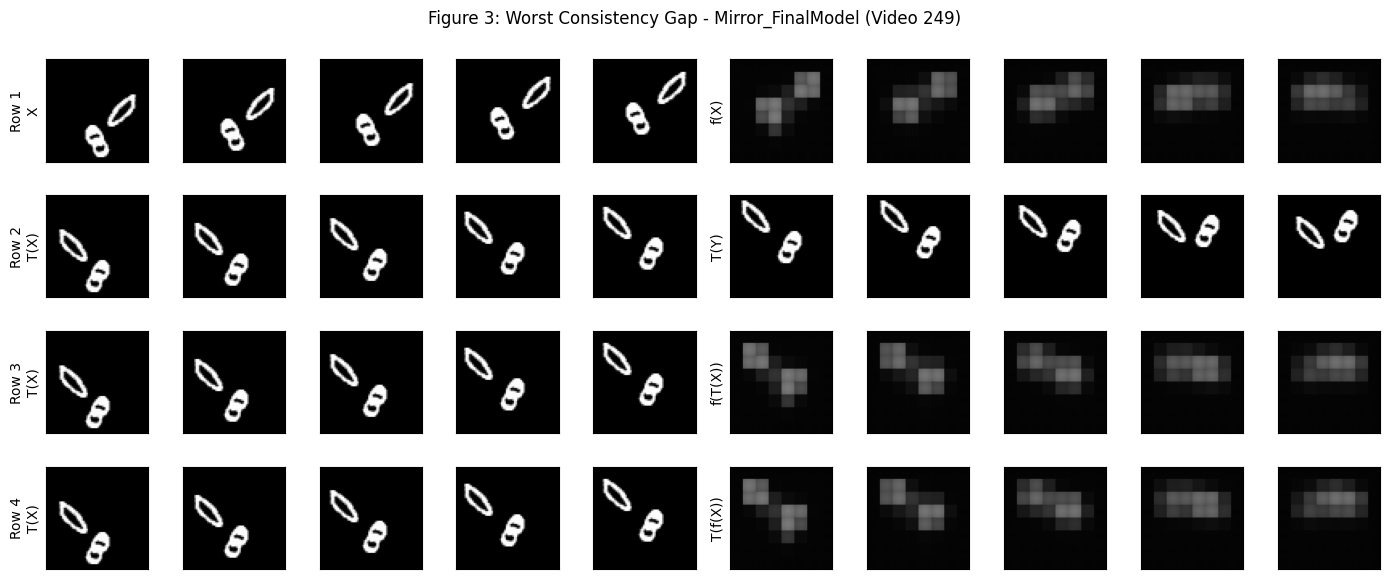

Saved animated GIF: gifs/worst_consistency_Mirror_FinalModel_vid249.gif


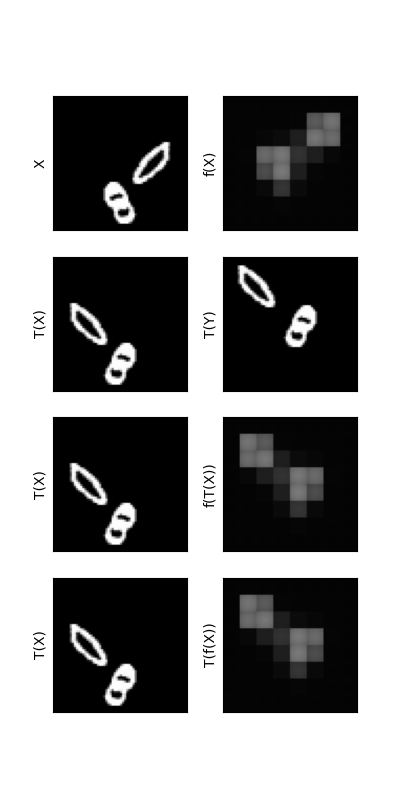

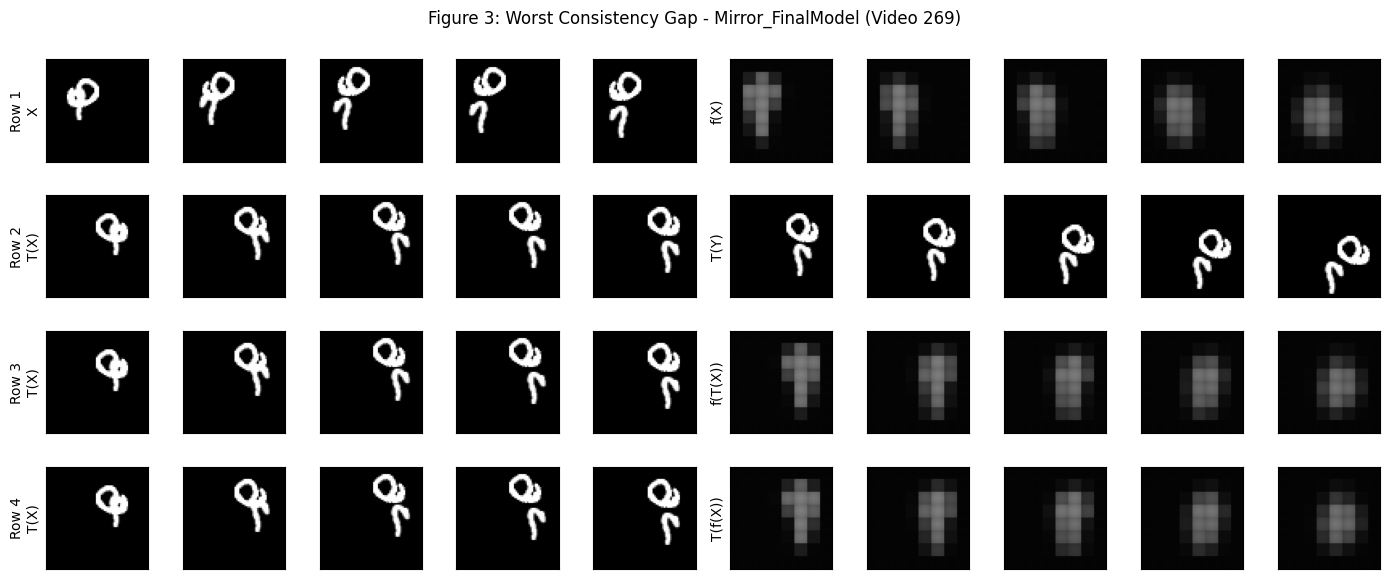

Saved animated GIF: gifs/worst_consistency_Mirror_FinalModel_vid269.gif


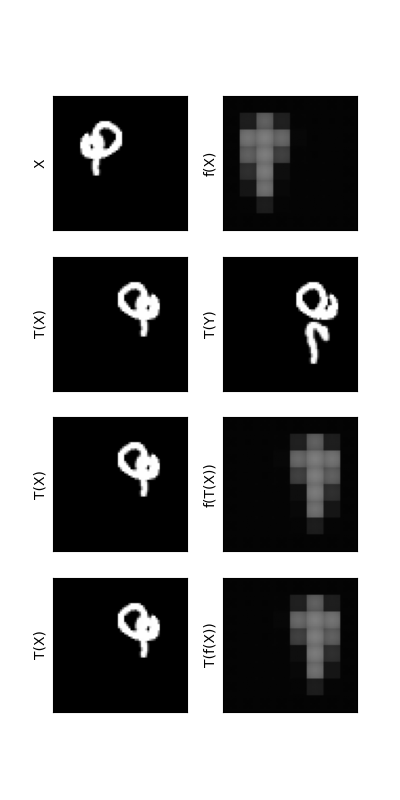


Evaluating Rotation Symmetry (Worst cases from Baseline):


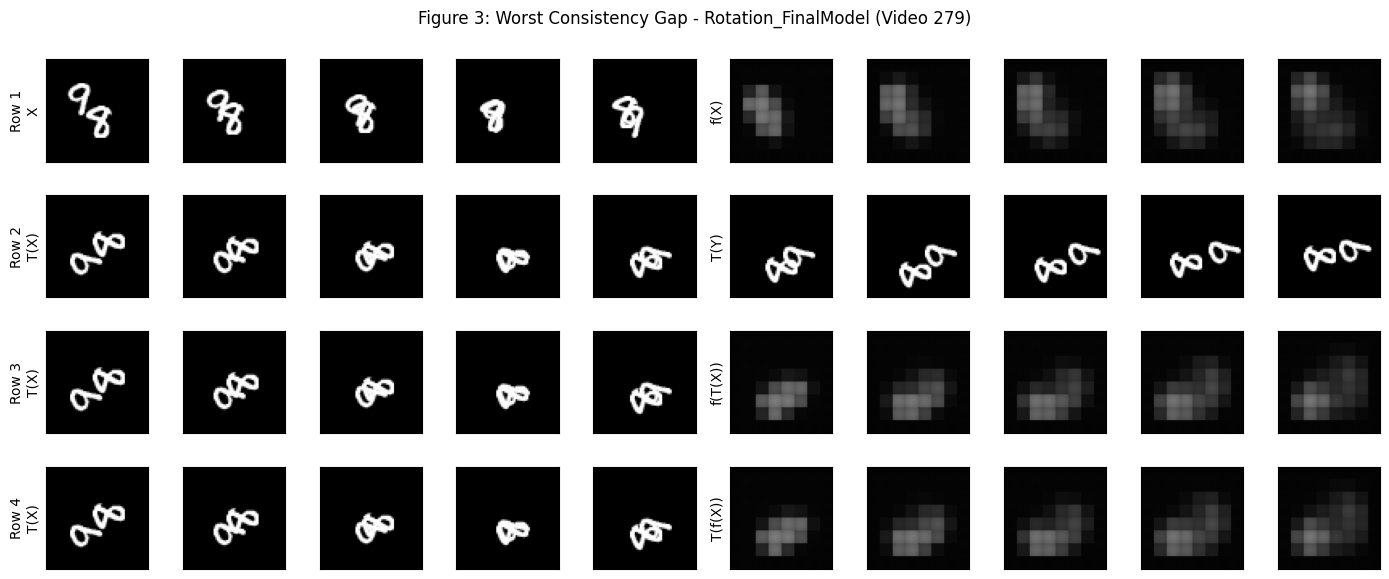

Saved animated GIF: gifs/worst_consistency_Rotation_FinalModel_vid279.gif


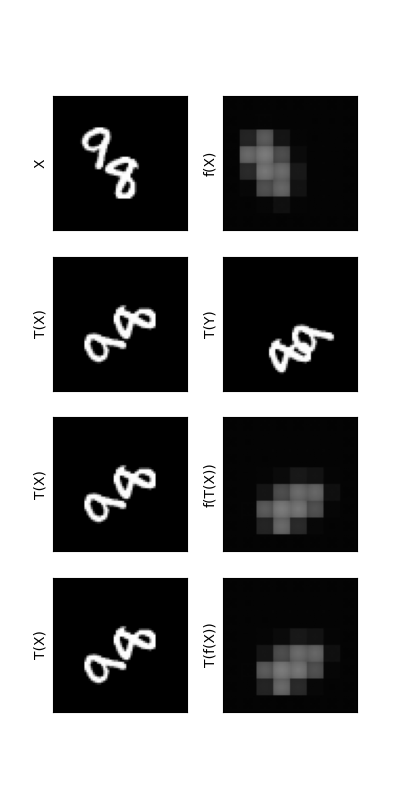

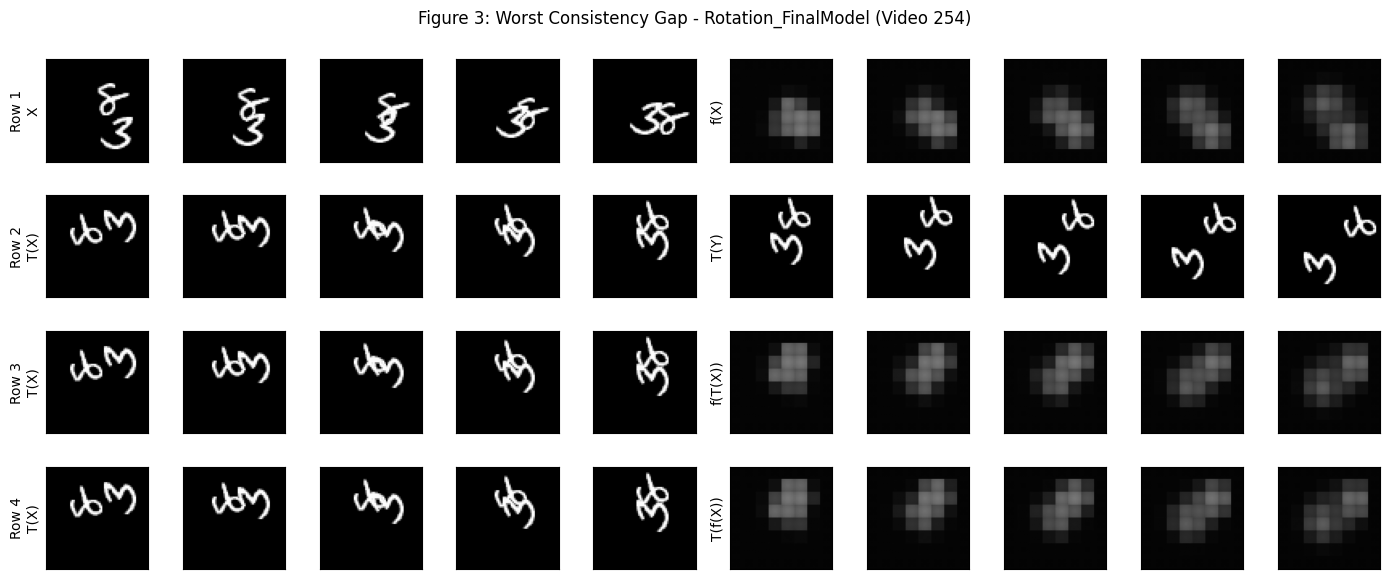

Saved animated GIF: gifs/worst_consistency_Rotation_FinalModel_vid254.gif


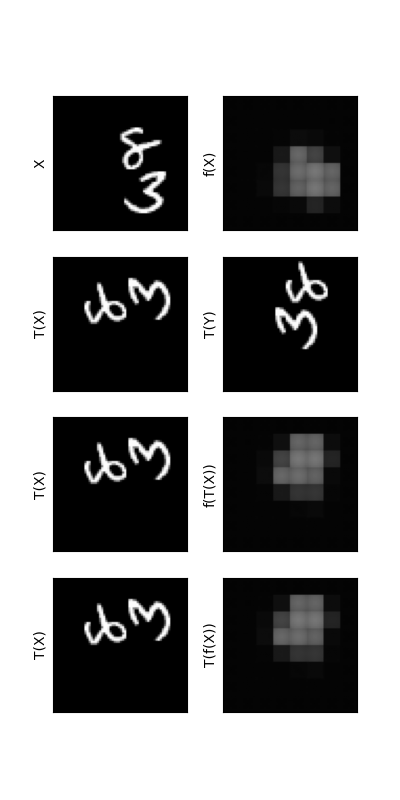


--- Generating Figure 6b (Final Model on Multi-Speed Video) ---


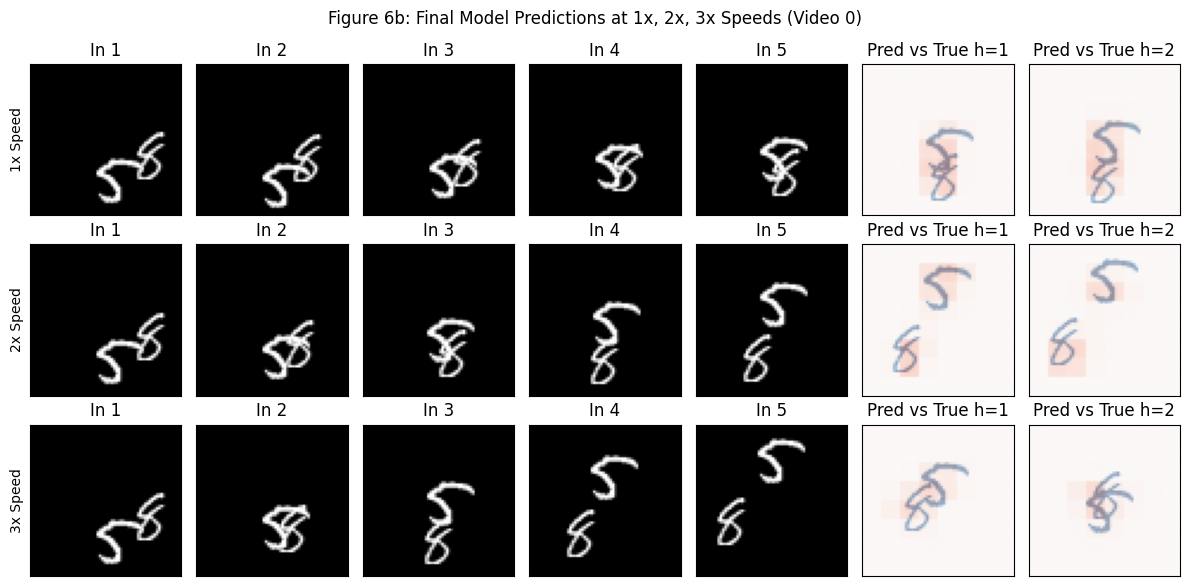

In [29]:
import os
from IPython.display import Image, display

print("\n--- Generating Figure 6a (Final Model on Worst Consistency Videos) ---")
# Re-use top2_CM_idx and top2_CR_idx from Part 3

print("\nEvaluating Mirror Symmetry (Worst cases from Baseline):")
for idx in top2_CM_idx:
    transform_name = "Mirror_FinalModel"
    plot_and_gif_consistency(sym_db0, test_dataset, idx, transform_mirror, transform_name, device)
    
    # Render the saved GIF natively in the notebook
    gif_path = f"gifs/worst_consistency_{transform_name}_vid{idx}.gif"
    if os.path.exists(gif_path):
        display(Image(filename=gif_path))

print("\nEvaluating Rotation Symmetry (Worst cases from Baseline):")
for idx in top2_CR_idx:
    transform_name = "Rotation_FinalModel"
    plot_and_gif_consistency(sym_db0, test_dataset, idx, transform_rotate, transform_name, device)
    
    # Render the saved GIF natively in the notebook
    gif_path = f"gifs/worst_consistency_{transform_name}_vid{idx}.gif"
    if os.path.exists(gif_path):
        display(Image(filename=gif_path))

print("\n--- Generating Figure 6b (Final Model on Multi-Speed Video) ---")
# Re-use no_overlap_idx from Part 3
video_clean = test_dataset[no_overlap_idx]
fig, axes = plt.subplots(3, 7, figsize=(12, 6))
speeds = [1, 2, 3]

for r, k in enumerate(speeds):
    X, Y, _, _ = extract_window(video_clean, t=1, k=k)
    X = X.unsqueeze(0).to(device)
    
    with torch.no_grad():
        Y_hat = sym_db0(X)
        
    X_np = X.cpu().squeeze().numpy()
    Y_hat_np = Y_hat.cpu().squeeze().numpy()[:2]
    Y_true_np = Y.cpu().squeeze().numpy()[:2]
    
    axes[r, 0].set_ylabel(f"{k}x Speed")
    for c in range(5):
        axes[r, c].imshow(X_np[c], cmap='gray', vmin=0, vmax=1)
        axes[r, c].set_title(f"In {c+1}")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        
    axes[r, 5].imshow(Y_hat_np[0], cmap='Reds', alpha=0.6, vmin=0, vmax=1)
    axes[r, 5].imshow(Y_true_np[0], cmap='Blues', alpha=0.4, vmin=0, vmax=1)
    axes[r, 5].set_title("Pred vs True h=1")
    axes[r, 5].set_xticks([]); axes[r, 5].set_yticks([])

    axes[r, 6].imshow(Y_hat_np[1], cmap='Reds', alpha=0.6, vmin=0, vmax=1)
    axes[r, 6].imshow(Y_true_np[1], cmap='Blues', alpha=0.4, vmin=0, vmax=1)
    axes[r, 6].set_title("Pred vs True h=2")
    axes[r, 6].set_xticks([]); axes[r, 6].set_yticks([])

plt.suptitle(f"Figure 6b: Final Model Predictions at 1x, 2x, 3x Speeds (Video {no_overlap_idx})")
plt.tight_layout()
plt.show()